
# ANMS và Region Growing cổ điển

**Môn học:** Thị giác máy tính (121036)

**Bài tập 2:** Đặc trưng góc và phân vùng ảnh

## Nội dung thực hiện

- Cài đặt Adaptive Non-Maximal Suppression (`anms`).
- Kiểm chứng A5: So sánh Top-N và ANMS.
- Cài đặt Region Growing cổ điển (`region_growing_classic`).
- Kiểm chứng B4: So sánh Stack và Queue.

## Nguồn và sử dụng AI

Các hàm Harris cổ điển được sử dụng từ notebook `Harris_classic.ipynb` của Người 2, không chỉnh sửa thuật toán.

Phần cài đặt và thí nghiệm của Người 4 có sự hỗ trợ của ChatGPT ngày 14/11/2026.

Việc sử dụng AI trong phần cài đặt cần được xác nhận theo quy định cập nhật của giảng viên.



## 0. Harris cổ điển — hàm dùng chung của Người 2

Các cell sau sử dụng nguyên văn code `gaussian_blur`, `structure_tensor`, `harris_response`, `nms_2d`, `harris_classic`, `top_n` từ notebook Người 2 để notebook Người 4 có thể chạy độc lập khi kiểm chứng.

Không sửa các hàm này trong phần Người 4.

In [4]:

import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

def gaussian_blur(img, sigma):
    """Làm mờ Gauss. Được phép gọi scipy.ndimage.gaussian_filter."""
    return gaussian_filter(np.asarray(img, dtype=float), sigma=sigma)

def structure_tensor(img, sigma_i, sigma_d):
    """Ma trận mô-men bậc hai theo công thức (1), đã nhân sigma_d**2.
    sigma_d: độ mờ trước khi lấy đạo hàm.
    sigma_i: bán kính cửa sổ lấy trung bình các tích đạo hàm.
    -> (Mxx, Mxy, Myy), mỗi phần tử cùng kích thước ảnh.
    """
    # L = G(sigma_d) * I
    L = gaussian_blur(img, sigma_d)

    # Lx, Ly: sai phân trung tâm ở trong ảnh, sai phân một phía ở viền
    # (np.gradient) -> không còn đạo hàm bị gán cứng bằng 0 ở viền.
    Ly, Lx = np.gradient(L)          # axis 0 = hàng (y), axis 1 = cột (x)

    # G(sigma_i) * [Lx^2, LxLy, Ly^2]
    Mxx = gaussian_blur(Lx * Lx, sigma_i)
    Mxy = gaussian_blur(Lx * Ly, sigma_i)
    Myy = gaussian_blur(Ly * Ly, sigma_i)

    # Chuẩn hóa tỉ lệ Lindeberg: nhân sigma_d^2
    scale = sigma_d ** 2
    return Mxx * scale, Mxy * scale, Myy * scale

def harris_response(img, sigma_i, sigma_d, k=0.04):
    """Đáp ứng R theo công thức (2). -> mảng float cùng kích thước ảnh."""
    Mxx, Mxy, Myy = structure_tensor(img, sigma_i, sigma_d)
    det = Mxx * Myy - Mxy ** 2
    trace = Mxx + Myy
    return det - k * trace ** 2

def nms_2d(response, window=3):
    """Cực đại địa phương trong cửa sổ window x window. -> mảng bool.

    Tất định khi đồng hạng: nếu nhiều pixel trong cùng một cửa sổ có cùng
    giá trị lớn nhất thì chỉ giữ pixel đầu tiên theo thứ tự quét
    (hàng trước, cột sau). Pixel phải lớn HƠN NGHIÊM NGẶT các lân cận
    đứng trước nó và lớn hơn hoặc bằng các lân cận đứng sau nó.
    Vector hóa bằng cách dịch ảnh, không dùng vòng for theo pixel.
    """
    if window % 2 != 1 or window < 1:
        raise ValueError("window phải là số lẻ.")
    response = np.asarray(response, dtype=float)
    h, w = response.shape
    r = window // 2

    padded = np.pad(response, r, mode='constant', constant_values=-np.inf)
    mask = np.ones((h, w), dtype=bool)

    for dy in range(-r, r + 1):
        for dx in range(-r, r + 1):
            if dy == 0 and dx == 0:
                continue
            nb = padded[r + dy:r + dy + h, r + dx:r + dx + w]
            earlier = (dy < 0) or (dy == 0 and dx < 0)
            mask &= (response > nb) if earlier else (response >= nb)
    return mask

def harris_classic(img, sigma_i=2.0, sigma_d=1.4,
                   k=0.04, thresh_rel=0.01):
    """Harris một tỉ lệ: R -> nms_2d -> ngưỡng tương đối theo max(R).
    -> mảng (N, 3): (row, col, response), sắp xếp giảm dần theo response.
    (row, col) lưu dạng float; ép .astype(int) khi dùng làm chỉ số.
    """
    R = harris_response(img, sigma_i, sigma_d, k)

    max_R = R.max()
    if max_R <= 0:
        return np.empty((0, 3), dtype=float)

    mask = nms_2d(R, window=3) & (R > thresh_rel * max_R)

    rows, cols = np.nonzero(mask)
    corners = np.column_stack((rows, cols, R[rows, cols])).astype(float)

    # Giảm dần theo response; đồng hạng giữ thứ tự quét (sort ổn định)
    order = np.argsort(-corners[:, 2], kind='stable')
    return corners[order]

def top_n(points, n_keep):
    """Đường cơ sở để so với anms: lấy n_keep điểm mạnh nhất.
    points: mảng (N, 3) (row, col, response). -> mảng (n_keep, 3).
    Nếu N < n_keep thì trả về toàn bộ N điểm.
    """
    points = np.asarray(points, dtype=float)
    order = np.argsort(-points[:, 2], kind='stable')
    return points[order[:n_keep]]


ModuleNotFoundError: No module named 'cv2'


## 1. Phần A2 — Adaptive Non-Maximal Suppression (ANMS)

### 1.1. Mục tiêu

Thuật toán Harris cổ điển phát hiện các điểm góc dựa trên giá trị đáp ứng góc (Harris response).

Tuy nhiên, nếu chỉ chọn `N` điểm có response lớn nhất bằng `top_n()`, các điểm có thể tập trung vào vùng tương phản mạnh, trong khi những vùng tương phản yếu hơn không được đại diện.

**ANMS (Adaptive Non-Maximal Suppression)** giải quyết hạn chế này bằng cách xếp hạng các điểm theo bán kính triệt tiêu thay vì chỉ theo response.

### 1.2. Công thức ANMS

Theo công thức (4) trong tài liệu:

$$
r_i =
\min_{j:\,f_i < c_{\mathrm{robust}} f_j}
\|x_i-x_j\|
$$

Trong đó:

- $x_i$: vị trí điểm góc đang xét, theo tọa độ `(row, col)`.
- $x_j$: vị trí một điểm góc khác.
- $f_i$: Harris response của điểm $i$.
- $f_j$: Harris response của điểm $j$.
- $c_{\mathrm{robust}}$: hệ số xác định mức độ mạnh hơn đáng kể, mặc định bằng $0.9$.
- $r_i$: khoảng cách nhỏ nhất từ điểm $i$ đến một điểm mạnh hơn đáng kể.

Khoảng cách Euclid giữa hai điểm được tính bằng:

$$
d(i,j)=\sqrt{(row_i-row_j)^2+(col_i-col_j)^2}
$$

Nếu không tồn tại điểm $j$ thỏa điều kiện $f_i<c_{\mathrm{robust}}f_j$, đặt $r_i=\infty$.

### 1.3. Các bước xử lý

1. Nhận danh sách điểm góc từ `harris_classic()`, có dạng `(N, 3)`.
2. Với từng điểm $i$, xác định các điểm $j$ có response mạnh hơn đáng kể.
3. Tính khoảng cách Euclid từ điểm $i$ đến từng điểm $j$ hợp lệ.
4. Lấy khoảng cách nhỏ nhất làm bán kính $r_i$.
5. Sắp xếp các điểm theo $r_i$ giảm dần.
6. Giữ `n_keep` điểm đầu tiên.

Kết quả trả về vẫn có ba cột:

`(row, col, response)`

Bán kính $r_i$ chỉ được sử dụng để xếp hạng, không được thêm vào mảng kết quả.

### 1.4. Ý nghĩa của c_robust

Với $c_{\mathrm{robust}}=0.9$, một điểm khác phải có response lớn hơn khoảng $1/0.9 \approx 1.111$ lần response của điểm đang xét mới có thể triệt tiêu nó.

Khi $c_{\mathrm{robust}}$ thay đổi, tập điểm được phép triệt tiêu cũng thay đổi, dẫn đến thay đổi bán kính và thứ tự chọn điểm.

### 1.5. So sánh với Top-N

- **Top-N:** Ưu tiên điểm có response lớn nhất.
- **ANMS:** Ưu tiên điểm có bán kính triệt tiêu lớn nhất.

Vì vậy, ANMS có thể giữ một điểm có response thấp hơn nhưng nằm xa các điểm mạnh, góp phần cải thiện độ phủ không gian.

Trong phần kiểm chứng A5, hai phương pháp sẽ được so sánh trên cùng tập điểm Harris và cùng số lượng điểm được giữ bằng chỉ số `grid_occupancy`.


In [ ]:
def anms(points, n_keep, c_robust=0.9):
    """Select corners based on their distance from stronger corners."""
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or points.shape[1] != 3:
        raise ValueError("points phải có kích thước (N, 3)")
    if not 0 < c_robust <= 1:
        raise ValueError("c_robust phải thuộc khoảng (0, 1]")
    if n_keep < 0:
        raise ValueError("n_keep không được âm")

    n_keep = min(n_keep, len(points))
    if n_keep == 0:
        return np.empty((0, 3), dtype=float)

    radii = np.full(len(points), np.inf)
    for i, (row, col, response) in enumerate(points):
        for j, (other_row, other_col, other_response) in enumerate(points):
            if i == j or response >= c_robust * other_response:
                continue

            distance = np.hypot(row - other_row, col - other_col)
            radii[i] = min(radii[i], distance)

    # Stable sorting keeps the original order when two radii are equal.
    selected = np.argsort(-radii, kind="stable")[:n_keep]
    return points[selected].copy()


**Prompt hỗ trợ AI cho phần thí nghiệm :**

> Hãy hỗ trợ thiết kế một kiểm chứng nhỏ cho hàm ANMS với bốn điểm góc giả lập có dạng (row, col, response). Chọn ba điểm bằng ANMS và Top-N, in kết quả và giải thích cách đối chiếu mà không sửa hàm anms hay top_n.



In [ ]:
#  Kiểm chứng ANMS trên dữ liệu mẫu

# Mỗi hàng gồm: row, col, Harris response
points_test = np.array([
    [10, 10, 100],  # A
    [12, 10,  95],  # B
    [50, 50,  60],  # C
    [90, 90,  40]   # D
], dtype=float)

# Giữ 3 điểm bằng ANMS
result_anms = anms(
    points_test,
    n_keep=3,
    c_robust=0.9
)

# Giữ 3 điểm bằng Top-N để đối chiếu
result_top_n = top_n(points_test, n_keep=3)

print("=== TOP-N ===")
print(result_top_n)

print("\n=== ANMS ===")
print(result_anms)

expected = points_test[[0, 1, 3]]

assert result_anms.shape == (3, 3), "Sai kích thước output"

assert np.array_equal(
    result_anms, expected
), "ANMS chưa chọn đúng A, B, D"

assert np.array_equal(
    points_test,
    np.array([
        [10, 10, 100],
        [12, 10,  95],
        [50, 50,  60],
        [90, 90,  40]
    ], dtype=float)
), "Hàm ANMS đã thay đổi dữ liệu đầu vào"

print("\nPASS: ANMS chọn đúng A, B, D.")
print("PASS: Output có kích thước (3, 3).")
print("PASS: Dữ liệu đầu vào không bị thay đổi.")


=== TOP-N ===
[[ 10.  10. 100.]
 [ 12.  10.  95.]
 [ 50.  50.  60.]]

=== ANMS ===
[[ 10.  10. 100.]
 [ 12.  10.  95.]
 [ 90.  90.  40.]]

PASS: ANMS chọn đúng A, B, D.
PASS: Output có kích thước (3, 3).
PASS: Dữ liệu đầu vào không bị thay đổi.


## 2. Kiểm chứng A5 — Top-N vs ANMS

### Chuẩn bị ảnh thí nghiệm

Thí nghiệm sử dụng ảnh xám tổng hợp có hai vùng:
- Bên trái: tương phản mạnh.
- Bên phải: tương phản yếu.

Mục đích là kiểm tra xem Top-N có tập trung điểm ở vùng tương phản mạnh hay không và ANMS có giúp phân bố điểm đều hơn hay không.

Cả hai phương pháp sẽ sử dụng cùng tập điểm ứng viên từ Harris cổ điển.

**Prompt hỗ trợ AI cho phần thí nghiệm :**

> Hãy hỗ trợ xây dựng ảnh xám tổng hợp 256 × 256 có hai nửa với độ tương phản khác nhau để kiểm chứng Top-N và ANMS. Sử dụng seed cố định để tái lập kết quả, phát hiện ứng viên bằng hàm Harris có sẵn và trực quan hóa hai nhóm điểm trên cùng ảnh. Không chỉnh sửa phần cài đặt thuật toán.



=== CHUẨN BỊ THÍ NGHIỆM A5 ===
Kích thước ảnh: (256, 256)
Số điểm Harris ứng viên: 196
Số điểm cần giữ: 40
Kích thước mảng candidates: (196, 3)


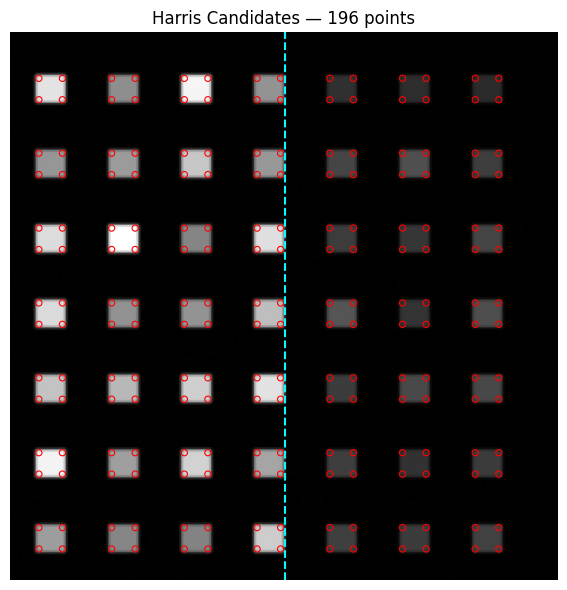

In [ ]:
def make_contrast_scene(size=256, seed=7):
    """
    Tạo ảnh xám có hai vùng tương phản khác nhau.

    Bên trái: tương phản mạnh.
    Bên phải: tương phản yếu.
    """
    rng = np.random.default_rng(seed)

    # Nền ảnh xám
    img = np.full((size, size), 115.0)

    # Nhiễu nhẹ để ảnh gần dữ liệu thực tế hơn
    img += rng.normal(0, 0.35, img.shape)

    for r in range(20, size - 20, 35):
        for c in range(12, size - 10, 34):

            h, w = 13, 14

            if c < size // 2:
                # Nửa trái: tương phản mạnh
                delta = rng.uniform(65, 135)
            else:
                # Nửa phải: tương phản yếu
                delta = rng.uniform(18, 45)

            img[r:r+h, c:c+w] = 115 + delta

    # Làm mờ nhẹ
    return gaussian_blur(img, sigma=0.65)

scene = make_contrast_scene(size=256, seed=7)

candidates = harris_classic(
    scene,
    sigma_i=1.6,
    sigma_d=1.12,
    thresh_rel=0.00005
)

keep = min(40, len(candidates))

print("=== CHUẨN BỊ THÍ NGHIỆM A5 ===")
print("Kích thước ảnh:", scene.shape)
print("Số điểm Harris ứng viên:", len(candidates))
print("Số điểm cần giữ:", keep)
print("Kích thước mảng candidates:", candidates.shape)

plt.figure(figsize=(8, 6))

plt.imshow(scene, cmap="gray")

if len(candidates) > 0:
    plt.scatter(
        candidates[:, 1],  # col -> trục X
        candidates[:, 0],  # row -> trục Y
        s=20,
        facecolors="none",
        edgecolors="red",
        linewidths=0.8
    )

# Đường phân chia hai vùng tương phản
plt.axvline(
    scene.shape[1] / 2,
    color="cyan",
    linestyle="--",
    linewidth=1.5
)

plt.title(
    f"Harris Candidates — {len(candidates)} points"
)

plt.axis("off")
plt.tight_layout()
plt.show()


### A5 — So sánh Top-N và ANMS bằng Grid Occupancy

Chia ảnh thành lưới 8 × 8, tương ứng với 64 ô.

Grid Occupancy được tính bằng:

$$
\text{Grid Occupancy} =
\frac{\text{Số ô chứa ít nhất một điểm góc}}
{\text{Tổng số ô trong lưới}}
\times 100\%
$$

Hai phương pháp sử dụng:
- Cùng ảnh đầu vào.
- Cùng danh sách điểm Harris.
- Cùng số lượng điểm được chọn.
- Cùng kích thước lưới.

**Prompt hỗ trợ AI cho phần thí nghiệm:**

> Hãy hỗ trợ viết phép đo Grid Occupancy trên lưới 8 × 8 đối với tập điểm góc (row, col, response). Dùng cùng tập ứng viên Harris và cùng số lượng điểm được chọn để so sánh Top-N với ANMS; in số ô được phủ, tỷ lệ phần trăm và trực quan hóa kết quả.


=== A5: TOP-N VS ANMS ===
Số điểm Harris ứng viên: 196
Số điểm Top-N: 40
Số điểm ANMS: 40

Grid Occupancy Top-N: 20.31%
Grid Occupancy ANMS:  29.69%
Chênh lệch: +9.38 điểm phần trăm


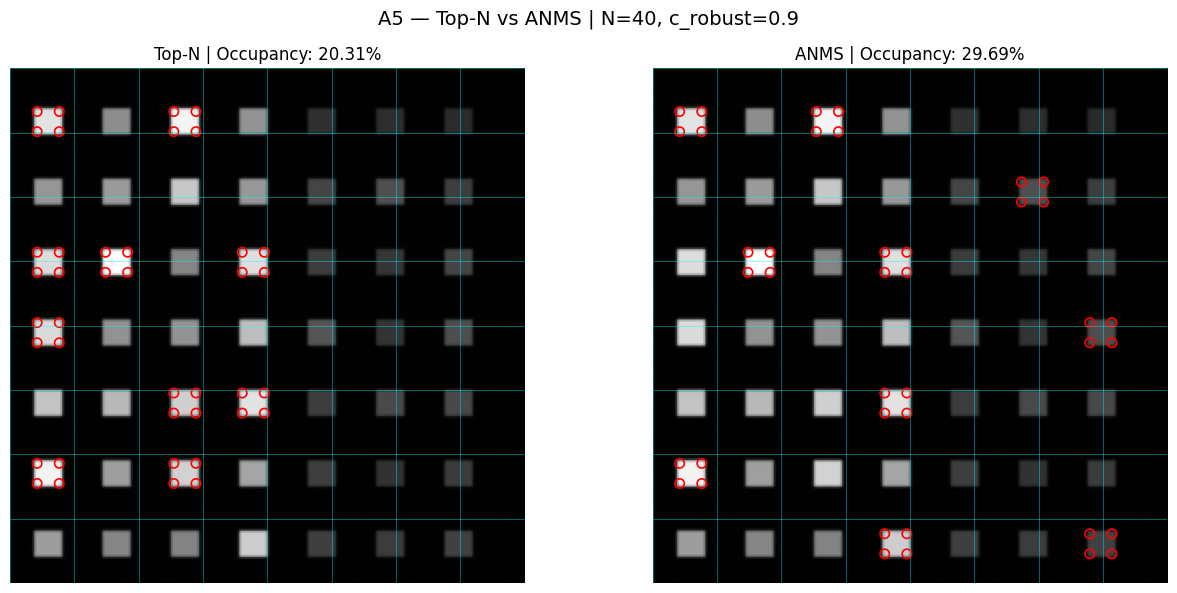

In [ ]:
def grid_occupancy(points, image_shape, grid_size=(8, 8)):
    """
    Đo tỷ lệ ô lưới có ít nhất một điểm góc.

    points: mảng (N, 3) gồm (row, col, response)
    image_shape: (height, width)
    grid_size: (số hàng lưới, số cột lưới)

    Trả về tỷ lệ phần trăm [0, 100].
    """
    height, width = image_shape[:2]
    grid_rows, grid_cols = grid_size

    occupied_cells = np.zeros(
        (grid_rows, grid_cols),
        dtype=bool
    )

    for row, col, _ in points:
        # Xác định ô lưới chứa điểm góc
        cell_row = min(int(row * grid_rows / height), grid_rows - 1)
        cell_col = min(int(col * grid_cols / width), grid_cols - 1)

        if 0 <= row < height and 0 <= col < width:
            occupied_cells[cell_row, cell_col] = True

    occupied_count = np.count_nonzero(occupied_cells)
    total_cells = grid_rows * grid_cols

    return occupied_count / total_cells * 100

points_top_n = top_n(candidates, n_keep=keep)

points_anms = anms(
    candidates,
    n_keep=keep,
    c_robust=0.9
)

# Đo Grid Occupancy
occupancy_top_n = grid_occupancy(
    points_top_n,
    scene.shape,
    grid_size=(8, 8)
)

occupancy_anms = grid_occupancy(
    points_anms,
    scene.shape,
    grid_size=(8, 8)
)

print("=== A5: TOP-N VS ANMS ===")
print(f"Số điểm Harris ứng viên: {len(candidates)}")
print(f"Số điểm Top-N: {len(points_top_n)}")
print(f"Số điểm ANMS: {len(points_anms)}")

print(f"\nGrid Occupancy Top-N: {occupancy_top_n:.2f}%")
print(f"Grid Occupancy ANMS:  {occupancy_anms:.2f}%")

print(
    f"Chênh lệch: "
    f"{occupancy_anms - occupancy_top_n:+.2f} điểm phần trăm"
)

assert len(points_top_n) == len(points_anms), (
    "Hai phương pháp phải giữ cùng số lượng điểm."
)

# Hàm trực quan hóa
def plot_selected_points(ax, image, points, title):
    ax.imshow(image, cmap="gray")

    if len(points) > 0:
        ax.scatter(
            points[:, 1],
            points[:, 0],
            s=45,
            facecolors="none",
            edgecolors="red",
            linewidths=1.2
        )

    height, width = image.shape[:2]

    for x in np.linspace(0, width, 9):
        ax.axvline(
            x - 0.5,
            color="cyan",
            alpha=0.4,
            linewidth=0.7
        )

    for y in np.linspace(0, height, 9):
        ax.axhline(
            y - 0.5,
            color="cyan",
            alpha=0.4,
            linewidth=0.7
        )

    ax.set_title(title)
    ax.set_xlim(-0.5, width - 0.5)
    ax.set_ylim(height - 0.5, -0.5)
    ax.axis("off")

# Trực quan hóa hai phương pháp
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

plot_selected_points(
    axes[0],
    scene,
    points_top_n,
    f"Top-N | Occupancy: {occupancy_top_n:.2f}%"
)

plot_selected_points(
    axes[1],
    scene,
    points_anms,
    f"ANMS | Occupancy: {occupancy_anms:.2f}%"
)

plt.suptitle(
    f"A5 — Top-N vs ANMS | N={keep}, c_robust=0.9",
    fontsize=14
)

plt.tight_layout()
plt.show()


### A5 — Khảo sát tham số c_robust và N

Thí nghiệm khảo sát hai yếu tố:

1. **Hệ số c_robust:** Điều chỉnh điều kiện một điểm có response đủ mạnh để triệt tiêu điểm khác.
2. **Số lượng điểm N:** Điều chỉnh số điểm góc được giữ sau khi chọn lọc.

**Phương pháp:**
- Sử dụng cùng ảnh và tập điểm Harris ứng viên.
- Đo Grid Occupancy bằng lưới 8 × 8.
- So sánh các giá trị của c_robust và N.
- Biểu diễn kết quả bằng biểu đồ đường.


# ANMS và Region Growing cổ điển

**Môn học:** Thị giác máy tính (121036)

**Bài tập 2:** Đặc trưng góc và phân vùng ảnh

## Nội dung thực hiện

- Cài đặt Adaptive Non-Maximal Suppression (`anms`).
- Kiểm chứng A5: So sánh Top-N và ANMS.
- Cài đặt Region Growing cổ điển (`region_growing_classic`).
- Kiểm chứng B4: So sánh Stack và Queue.

## Nguồn và sử dụng AI

Các hàm Harris cổ điển được sử dụng từ notebook `Harris_classic.ipynb` của Người 2, không chỉnh sửa thuật toán.

Phần cài đặt và thí nghiệm của Người 4 có sự hỗ trợ của ChatGPT ngày 14/11/2026.

Việc sử dụng AI trong phần cài đặt cần được xác nhận theo quy định cập nhật của giảng viên.



## 0. Harris cổ điển — hàm dùng chung của Người 2

Các cell sau sử dụng nguyên văn code `gaussian_blur`, `structure_tensor`, `harris_response`, `nms_2d`, `harris_classic`, `top_n` từ notebook Người 2 để notebook Người 4 có thể chạy độc lập khi kiểm chứng.

Không sửa các hàm này trong phần Người 4.

In [ ]:

import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

def gaussian_blur(img, sigma):
    """Làm mờ Gauss. Được phép gọi scipy.ndimage.gaussian_filter."""
    return gaussian_filter(np.asarray(img, dtype=float), sigma=sigma)

def structure_tensor(img, sigma_i, sigma_d):
    """Ma trận mô-men bậc hai theo công thức (1), đã nhân sigma_d**2.
    sigma_d: độ mờ trước khi lấy đạo hàm.
    sigma_i: bán kính cửa sổ lấy trung bình các tích đạo hàm.
    -> (Mxx, Mxy, Myy), mỗi phần tử cùng kích thước ảnh.
    """
    # L = G(sigma_d) * I
    L = gaussian_blur(img, sigma_d)

    # Lx, Ly: sai phân trung tâm ở trong ảnh, sai phân một phía ở viền
    # (np.gradient) -> không còn đạo hàm bị gán cứng bằng 0 ở viền.
    Ly, Lx = np.gradient(L)          # axis 0 = hàng (y), axis 1 = cột (x)

    # G(sigma_i) * [Lx^2, LxLy, Ly^2]
    Mxx = gaussian_blur(Lx * Lx, sigma_i)
    Mxy = gaussian_blur(Lx * Ly, sigma_i)
    Myy = gaussian_blur(Ly * Ly, sigma_i)

    # Chuẩn hóa tỉ lệ Lindeberg: nhân sigma_d^2
    scale = sigma_d ** 2
    return Mxx * scale, Mxy * scale, Myy * scale

def harris_response(img, sigma_i, sigma_d, k=0.04):
    """Đáp ứng R theo công thức (2). -> mảng float cùng kích thước ảnh."""
    Mxx, Mxy, Myy = structure_tensor(img, sigma_i, sigma_d)
    det = Mxx * Myy - Mxy ** 2
    trace = Mxx + Myy
    return det - k * trace ** 2

def nms_2d(response, window=3):
    """Cực đại địa phương trong cửa sổ window x window. -> mảng bool.

    Tất định khi đồng hạng: nếu nhiều pixel trong cùng một cửa sổ có cùng
    giá trị lớn nhất thì chỉ giữ pixel đầu tiên theo thứ tự quét
    (hàng trước, cột sau). Pixel phải lớn HƠN NGHIÊM NGẶT các lân cận
    đứng trước nó và lớn hơn hoặc bằng các lân cận đứng sau nó.
    Vector hóa bằng cách dịch ảnh, không dùng vòng for theo pixel.
    """
    if window % 2 != 1 or window < 1:
        raise ValueError("window phải là số lẻ.")
    response = np.asarray(response, dtype=float)
    h, w = response.shape
    r = window // 2

    padded = np.pad(response, r, mode='constant', constant_values=-np.inf)
    mask = np.ones((h, w), dtype=bool)

    for dy in range(-r, r + 1):
        for dx in range(-r, r + 1):
            if dy == 0 and dx == 0:
                continue
            nb = padded[r + dy:r + dy + h, r + dx:r + dx + w]
            earlier = (dy < 0) or (dy == 0 and dx < 0)
            mask &= (response > nb) if earlier else (response >= nb)
    return mask

def harris_classic(img, sigma_i=2.0, sigma_d=1.4,
                   k=0.04, thresh_rel=0.01):
    """Harris một tỉ lệ: R -> nms_2d -> ngưỡng tương đối theo max(R).
    -> mảng (N, 3): (row, col, response), sắp xếp giảm dần theo response.
    (row, col) lưu dạng float; ép .astype(int) khi dùng làm chỉ số.
    """
    R = harris_response(img, sigma_i, sigma_d, k)

    max_R = R.max()
    if max_R <= 0:
        return np.empty((0, 3), dtype=float)

    mask = nms_2d(R, window=3) & (R > thresh_rel * max_R)

    rows, cols = np.nonzero(mask)
    corners = np.column_stack((rows, cols, R[rows, cols])).astype(float)

    # Giảm dần theo response; đồng hạng giữ thứ tự quét (sort ổn định)
    order = np.argsort(-corners[:, 2], kind='stable')
    return corners[order]

def top_n(points, n_keep):
    """Đường cơ sở để so với anms: lấy n_keep điểm mạnh nhất.
    points: mảng (N, 3) (row, col, response). -> mảng (n_keep, 3).
    Nếu N < n_keep thì trả về toàn bộ N điểm.
    """
    points = np.asarray(points, dtype=float)
    order = np.argsort(-points[:, 2], kind='stable')
    return points[order[:n_keep]]



## 1. Phần A2 — Adaptive Non-Maximal Suppression (ANMS)

### 1.1. Mục tiêu

Thuật toán Harris cổ điển phát hiện các điểm góc dựa trên giá trị đáp ứng góc (Harris response).

Tuy nhiên, nếu chỉ chọn `N` điểm có response lớn nhất bằng `top_n()`, các điểm có thể tập trung vào vùng tương phản mạnh, trong khi những vùng tương phản yếu hơn không được đại diện.

**ANMS (Adaptive Non-Maximal Suppression)** giải quyết hạn chế này bằng cách xếp hạng các điểm theo bán kính triệt tiêu thay vì chỉ theo response.

### 1.2. Công thức ANMS

Theo công thức (4) trong tài liệu:

$$
r_i =
\min_{j:\,f_i < c_{\mathrm{robust}} f_j}
\|x_i-x_j\|
$$

Trong đó:

- $x_i$: vị trí điểm góc đang xét, theo tọa độ `(row, col)`.
- $x_j$: vị trí một điểm góc khác.
- $f_i$: Harris response của điểm $i$.
- $f_j$: Harris response của điểm $j$.
- $c_{\mathrm{robust}}$: hệ số xác định mức độ mạnh hơn đáng kể, mặc định bằng $0.9$.
- $r_i$: khoảng cách nhỏ nhất từ điểm $i$ đến một điểm mạnh hơn đáng kể.

Khoảng cách Euclid giữa hai điểm được tính bằng:

$$
d(i,j)=\sqrt{(row_i-row_j)^2+(col_i-col_j)^2}
$$

Nếu không tồn tại điểm $j$ thỏa điều kiện $f_i<c_{\mathrm{robust}}f_j$, đặt $r_i=\infty$.

### 1.3. Các bước xử lý

1. Nhận danh sách điểm góc từ `harris_classic()`, có dạng `(N, 3)`.
2. Với từng điểm $i$, xác định các điểm $j$ có response mạnh hơn đáng kể.
3. Tính khoảng cách Euclid từ điểm $i$ đến từng điểm $j$ hợp lệ.
4. Lấy khoảng cách nhỏ nhất làm bán kính $r_i$.
5. Sắp xếp các điểm theo $r_i$ giảm dần.
6. Giữ `n_keep` điểm đầu tiên.

Kết quả trả về vẫn có ba cột:

`(row, col, response)`

Bán kính $r_i$ chỉ được sử dụng để xếp hạng, không được thêm vào mảng kết quả.

### 1.4. Ý nghĩa của c_robust

Với $c_{\mathrm{robust}}=0.9$, một điểm khác phải có response lớn hơn khoảng $1/0.9 \approx 1.111$ lần response của điểm đang xét mới có thể triệt tiêu nó.

Khi $c_{\mathrm{robust}}$ thay đổi, tập điểm được phép triệt tiêu cũng thay đổi, dẫn đến thay đổi bán kính và thứ tự chọn điểm.

### 1.5. So sánh với Top-N

- **Top-N:** Ưu tiên điểm có response lớn nhất.
- **ANMS:** Ưu tiên điểm có bán kính triệt tiêu lớn nhất.

Vì vậy, ANMS có thể giữ một điểm có response thấp hơn nhưng nằm xa các điểm mạnh, góp phần cải thiện độ phủ không gian.

Trong phần kiểm chứng A5, hai phương pháp sẽ được so sánh trên cùng tập điểm Harris và cùng số lượng điểm được giữ bằng chỉ số `grid_occupancy`.


In [ ]:
def anms(points, n_keep, c_robust=0.9):
    """Select corners based on their distance from stronger corners."""
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or points.shape[1] != 3:
        raise ValueError("points phải có kích thước (N, 3)")
    if not 0 < c_robust <= 1:
        raise ValueError("c_robust phải thuộc khoảng (0, 1]")
    if n_keep < 0:
        raise ValueError("n_keep không được âm")

    n_keep = min(n_keep, len(points))
    if n_keep == 0:
        return np.empty((0, 3), dtype=float)

    radii = np.full(len(points), np.inf)
    for i, (row, col, response) in enumerate(points):
        for j, (other_row, other_col, other_response) in enumerate(points):
            if i == j or response >= c_robust * other_response:
                continue

            distance = np.hypot(row - other_row, col - other_col)
            radii[i] = min(radii[i], distance)

    # Stable sorting keeps the original order when two radii are equal.
    selected = np.argsort(-radii, kind="stable")[:n_keep]
    return points[selected].copy()


**Prompt hỗ trợ AI cho phần thí nghiệm:**

> Hãy hỗ trợ thiết kế một kiểm chứng nhỏ cho hàm ANMS với bốn điểm góc giả lập có dạng (row, col, response). Chọn ba điểm bằng ANMS và Top-N, in kết quả và giải thích cách đối chiếu mà không sửa hàm anms hay top_n.

In [ ]:
#  Kiểm chứng ANMS trên dữ liệu mẫu

# Mỗi hàng gồm: row, col, Harris response
points_test = np.array([
    [10, 10, 100],  # A
    [12, 10,  95],  # B
    [50, 50,  60],  # C
    [90, 90,  40]   # D
], dtype=float)

# Giữ 3 điểm bằng ANMS
result_anms = anms(
    points_test,
    n_keep=3,
    c_robust=0.9
)

# Giữ 3 điểm bằng Top-N để đối chiếu
result_top_n = top_n(points_test, n_keep=3)

print("=== TOP-N ===")
print(result_top_n)

print("\n=== ANMS ===")
print(result_anms)

expected = points_test[[0, 1, 3]]

assert result_anms.shape == (3, 3), "Sai kích thước output"

assert np.array_equal(
    result_anms, expected
), "ANMS chưa chọn đúng A, B, D"

assert np.array_equal(
    points_test,
    np.array([
        [10, 10, 100],
        [12, 10,  95],
        [50, 50,  60],
        [90, 90,  40]
    ], dtype=float)
), "Hàm ANMS đã thay đổi dữ liệu đầu vào"

print("\nPASS: ANMS chọn đúng A, B, D.")
print("PASS: Output có kích thước (3, 3).")
print("PASS: Dữ liệu đầu vào không bị thay đổi.")


=== TOP-N ===
[[ 10.  10. 100.]
 [ 12.  10.  95.]
 [ 50.  50.  60.]]

=== ANMS ===
[[ 10.  10. 100.]
 [ 12.  10.  95.]
 [ 90.  90.  40.]]

PASS: ANMS chọn đúng A, B, D.
PASS: Output có kích thước (3, 3).
PASS: Dữ liệu đầu vào không bị thay đổi.


## 2. Kiểm chứng A5 — Top-N vs ANMS

### Chuẩn bị ảnh thí nghiệm

Thí nghiệm sử dụng ảnh xám tổng hợp có hai vùng:
- Bên trái: tương phản mạnh.
- Bên phải: tương phản yếu.

Mục đích là kiểm tra xem Top-N có tập trung điểm ở vùng tương phản mạnh hay không và ANMS có giúp phân bố điểm đều hơn hay không.

Cả hai phương pháp sẽ sử dụng cùng tập điểm ứng viên từ Harris cổ điển.

**Prompt hỗ trợ AI cho phần thí nghiệm:**

> Hãy hỗ trợ xây dựng ảnh xám tổng hợp 256 × 256 có hai nửa với độ tương phản khác nhau để kiểm chứng Top-N và ANMS. Sử dụng seed cố định để tái lập kết quả, phát hiện ứng viên bằng hàm Harris có sẵn và trực quan hóa hai nhóm điểm trên cùng ảnh. Không chỉnh sửa phần cài đặt thuật toán.

=== CHUẨN BỊ THÍ NGHIỆM A5 ===
Kích thước ảnh: (256, 256)
Số điểm Harris ứng viên: 196
Số điểm cần giữ: 40
Kích thước mảng candidates: (196, 3)


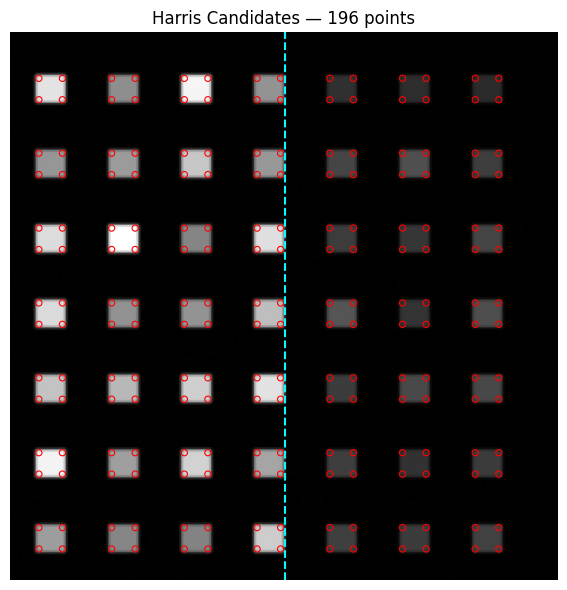

In [ ]:
def make_contrast_scene(size=256, seed=7):
    """
    Tạo ảnh xám có hai vùng tương phản khác nhau.

    Bên trái: tương phản mạnh.
    Bên phải: tương phản yếu.
    """
    rng = np.random.default_rng(seed)

    # Nền ảnh xám
    img = np.full((size, size), 115.0)

    # Nhiễu nhẹ để ảnh gần dữ liệu thực tế hơn
    img += rng.normal(0, 0.35, img.shape)

    for r in range(20, size - 20, 35):
        for c in range(12, size - 10, 34):

            h, w = 13, 14

            if c < size // 2:
                # Nửa trái: tương phản mạnh
                delta = rng.uniform(65, 135)
            else:
                # Nửa phải: tương phản yếu
                delta = rng.uniform(18, 45)

            img[r:r+h, c:c+w] = 115 + delta

    # Làm mờ nhẹ
    return gaussian_blur(img, sigma=0.65)

scene = make_contrast_scene(size=256, seed=7)

candidates = harris_classic(
    scene,
    sigma_i=1.6,
    sigma_d=1.12,
    thresh_rel=0.00005
)

keep = min(40, len(candidates))

print("=== CHUẨN BỊ THÍ NGHIỆM A5 ===")
print("Kích thước ảnh:", scene.shape)
print("Số điểm Harris ứng viên:", len(candidates))
print("Số điểm cần giữ:", keep)
print("Kích thước mảng candidates:", candidates.shape)

plt.figure(figsize=(8, 6))

plt.imshow(scene, cmap="gray")

if len(candidates) > 0:
    plt.scatter(
        candidates[:, 1],  # col -> trục X
        candidates[:, 0],  # row -> trục Y
        s=20,
        facecolors="none",
        edgecolors="red",
        linewidths=0.8
    )

# Đường phân chia hai vùng tương phản
plt.axvline(
    scene.shape[1] / 2,
    color="cyan",
    linestyle="--",
    linewidth=1.5
)

plt.title(
    f"Harris Candidates — {len(candidates)} points"
)

plt.axis("off")
plt.tight_layout()
plt.show()


### A5 — So sánh Top-N và ANMS bằng Grid Occupancy

Chia ảnh thành lưới 8 × 8, tương ứng với 64 ô.

Grid Occupancy được tính bằng:

$$
\text{Grid Occupancy} =
\frac{\text{Số ô chứa ít nhất một điểm góc}}
{\text{Tổng số ô trong lưới}}
\times 100\%
$$

Hai phương pháp sử dụng:
- Cùng ảnh đầu vào.
- Cùng danh sách điểm Harris.
- Cùng số lượng điểm được chọn.
- Cùng kích thước lưới.

**Prompt hỗ trợ AI cho phần thí nghiệm:**

> Hãy hỗ trợ viết phép đo Grid Occupancy trên lưới 8 × 8 đối với tập điểm góc (row, col, response). Dùng cùng tập ứng viên Harris và cùng số lượng điểm được chọn để so sánh Top-N với ANMS; in số ô được phủ, tỷ lệ phần trăm và trực quan hóa kết quả.

=== A5: TOP-N VS ANMS ===
Số điểm Harris ứng viên: 196
Số điểm Top-N: 40
Số điểm ANMS: 40

Grid Occupancy Top-N: 20.31%
Grid Occupancy ANMS:  29.69%
Chênh lệch: +9.38 điểm phần trăm


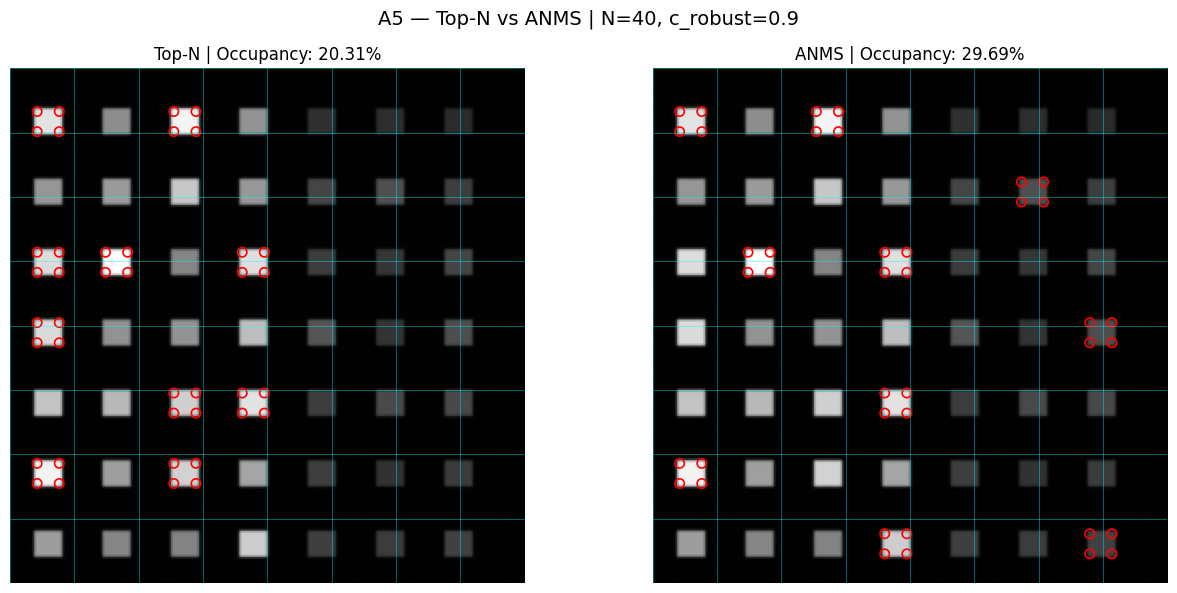

In [ ]:
def grid_occupancy(points, image_shape, grid_size=(8, 8)):
    """
    Đo tỷ lệ ô lưới có ít nhất một điểm góc.

    points: mảng (N, 3) gồm (row, col, response)
    image_shape: (height, width)
    grid_size: (số hàng lưới, số cột lưới)

    Trả về tỷ lệ phần trăm [0, 100].
    """
    height, width = image_shape[:2]
    grid_rows, grid_cols = grid_size

    occupied_cells = np.zeros(
        (grid_rows, grid_cols),
        dtype=bool
    )

    for row, col, _ in points:
        # Xác định ô lưới chứa điểm góc
        cell_row = min(int(row * grid_rows / height), grid_rows - 1)
        cell_col = min(int(col * grid_cols / width), grid_cols - 1)

        if 0 <= row < height and 0 <= col < width:
            occupied_cells[cell_row, cell_col] = True

    occupied_count = np.count_nonzero(occupied_cells)
    total_cells = grid_rows * grid_cols

    return occupied_count / total_cells * 100

points_top_n = top_n(candidates, n_keep=keep)

points_anms = anms(
    candidates,
    n_keep=keep,
    c_robust=0.9
)

# Đo Grid Occupancy
occupancy_top_n = grid_occupancy(
    points_top_n,
    scene.shape,
    grid_size=(8, 8)
)

occupancy_anms = grid_occupancy(
    points_anms,
    scene.shape,
    grid_size=(8, 8)
)

print("=== A5: TOP-N VS ANMS ===")
print(f"Số điểm Harris ứng viên: {len(candidates)}")
print(f"Số điểm Top-N: {len(points_top_n)}")
print(f"Số điểm ANMS: {len(points_anms)}")

print(f"\nGrid Occupancy Top-N: {occupancy_top_n:.2f}%")
print(f"Grid Occupancy ANMS:  {occupancy_anms:.2f}%")

print(
    f"Chênh lệch: "
    f"{occupancy_anms - occupancy_top_n:+.2f} điểm phần trăm"
)

assert len(points_top_n) == len(points_anms), (
    "Hai phương pháp phải giữ cùng số lượng điểm."
)

# Hàm trực quan hóa
def plot_selected_points(ax, image, points, title):
    ax.imshow(image, cmap="gray")

    if len(points) > 0:
        ax.scatter(
            points[:, 1],
            points[:, 0],
            s=45,
            facecolors="none",
            edgecolors="red",
            linewidths=1.2
        )

    height, width = image.shape[:2]

    for x in np.linspace(0, width, 9):
        ax.axvline(
            x - 0.5,
            color="cyan",
            alpha=0.4,
            linewidth=0.7
        )

    for y in np.linspace(0, height, 9):
        ax.axhline(
            y - 0.5,
            color="cyan",
            alpha=0.4,
            linewidth=0.7
        )

    ax.set_title(title)
    ax.set_xlim(-0.5, width - 0.5)
    ax.set_ylim(height - 0.5, -0.5)
    ax.axis("off")

# Trực quan hóa hai phương pháp
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

plot_selected_points(
    axes[0],
    scene,
    points_top_n,
    f"Top-N | Occupancy: {occupancy_top_n:.2f}%"
)

plot_selected_points(
    axes[1],
    scene,
    points_anms,
    f"ANMS | Occupancy: {occupancy_anms:.2f}%"
)

plt.suptitle(
    f"A5 — Top-N vs ANMS | N={keep}, c_robust=0.9",
    fontsize=14
)

plt.tight_layout()
plt.show()


### A5 — Khảo sát tham số c_robust và N

Thí nghiệm khảo sát hai yếu tố:

1. **Hệ số c_robust:** Điều chỉnh điều kiện một điểm có response đủ mạnh để triệt tiêu điểm khác.
2. **Số lượng điểm N:** Điều chỉnh số điểm góc được giữ sau khi chọn lọc.

**Phương pháp:**
- Sử dụng cùng ảnh và tập điểm Harris ứng viên.
- Đo Grid Occupancy bằng lưới 8 × 8.
- So sánh các giá trị của c_robust và N.
- Biểu diễn kết quả bằng biểu đồ đường.

**Prompt hỗ trợ AI cho phần thí nghiệm:**

> Hãy hỗ trợ thiết kế thí nghiệm thay đổi c_robust trong [0.7, 0.8, 0.9, 0.95, 1.0] và số điểm N trong [10, 20, 30, 40, 60, 80] cho ANMS. Giữ cùng ảnh, cùng tập điểm Harris, đo Grid Occupancy trên lưới 8 × 8, vẽ đồ thị và xử lý trường hợp số ứng viên nhỏ hơn N.

=== ẢNH HƯỞNG CỦA c_robust ===
N cố định = 40
c_robust = 0.70 | Occupancy = 29.69%
c_robust = 0.80 | Occupancy = 29.69%
c_robust = 0.90 | Occupancy = 29.69%
c_robust = 0.95 | Occupancy = 34.38%
c_robust = 1.00 | Occupancy = 59.38%

=== ẢNH HƯỞNG CỦA N ===
N  | Top-N (%) | ANMS (%)
10 |      6.25 |     6.25
20 |      9.38 |    14.06
30 |     17.19 |    23.44
40 |     20.31 |    29.69
60 |     29.69 |    51.56
80 |     37.50 |    68.75


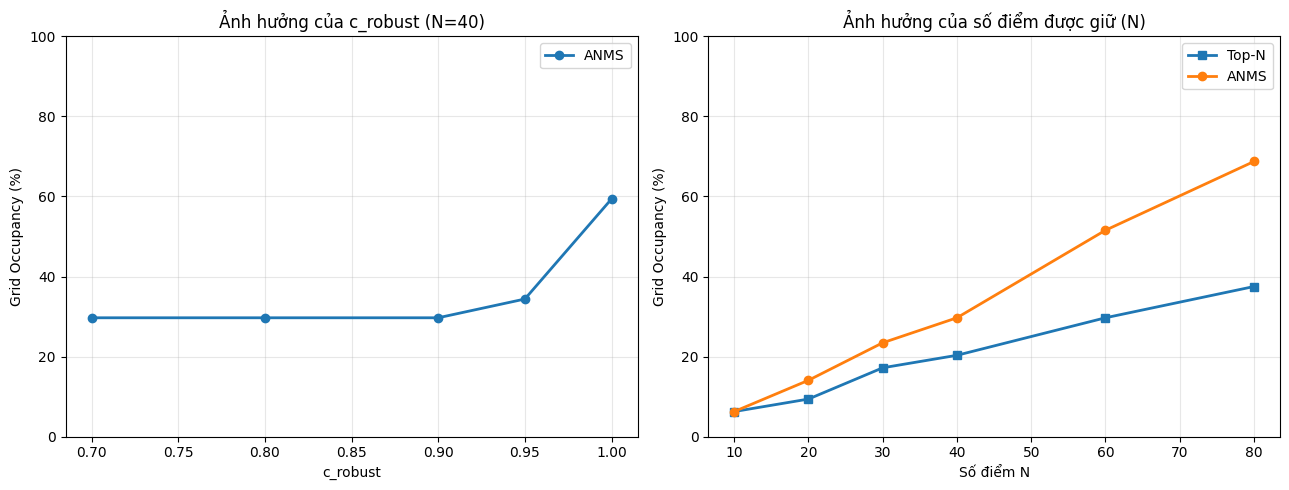

In [ ]:
# Khảo sát c_robust và số lượng điểm N

c_values = [0.7, 0.8, 0.9, 0.95, 1.0]
n_values = [10, 20, 30, 40, 60, 80]

# Không vượt quá số điểm Harris hiện có
n_values = [n for n in n_values if n <= len(candidates)]

grid_size = (8, 8)

# Thí nghiệm 1: Thay đổi c_robust, giữ cố định N

fixed_n = min(40, len(candidates))

occupancy_by_c = []

for c in c_values:
    selected = anms(
        candidates,
        n_keep=fixed_n,
        c_robust=c
    )

    occupancy = grid_occupancy(
        selected,
        scene.shape,
        grid_size=grid_size
    )

    occupancy_by_c.append(occupancy)

# Thí nghiệm 2: Thay đổi N, giữ c_robust = 0.9

occupancy_top_by_n = []
occupancy_anms_by_n = []

for n in n_values:

    selected_top = top_n(
        candidates,
        n_keep=n
    )

    selected_anms = anms(
        candidates,
        n_keep=n,
        c_robust=0.9
    )

    top_score = grid_occupancy(
        selected_top,
        scene.shape,
        grid_size=grid_size
    )

    anms_score = grid_occupancy(
        selected_anms,
        scene.shape,
        grid_size=grid_size
    )

    occupancy_top_by_n.append(top_score)
    occupancy_anms_by_n.append(anms_score)

print("=== ẢNH HƯỞNG CỦA c_robust ===")
print(f"N cố định = {fixed_n}")

for c, score in zip(c_values, occupancy_by_c):
    print(f"c_robust = {c:.2f} | Occupancy = {score:.2f}%")

print("\n=== ẢNH HƯỞNG CỦA N ===")
print("N  | Top-N (%) | ANMS (%)")

for n, top_score, anms_score in zip(
    n_values,
    occupancy_top_by_n,
    occupancy_anms_by_n
):
    print(
        f"{n:<3}| {top_score:>9.2f} | {anms_score:>8.2f}"
    )

# Biểu đồ kết quả

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ 1: c_robust
axes[0].plot(
    c_values,
    occupancy_by_c,
    marker="o",
    linewidth=2,
    label="ANMS"
)

axes[0].set_title(
    f"Ảnh hưởng của c_robust (N={fixed_n})"
)
axes[0].set_xlabel("c_robust")
axes[0].set_ylabel("Grid Occupancy (%)")
axes[0].set_ylim(0, 100)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Biểu đồ 2: N
axes[1].plot(
    n_values,
    occupancy_top_by_n,
    marker="s",
    linewidth=2,
    label="Top-N"
)

axes[1].plot(
    n_values,
    occupancy_anms_by_n,
    marker="o",
    linewidth=2,
    label="ANMS"
)

axes[1].set_title(
    "Ảnh hưởng của số điểm được giữ (N)"
)
axes[1].set_xlabel("Số điểm N")
axes[1].set_ylabel("Grid Occupancy (%)")
axes[1].set_ylim(0, 100)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


## 3. Tổng kết thí nghiệm A5 — Top-N vs ANMS

### 3.1. Nội dung đã thực hiện

Thí nghiệm sử dụng cùng một tập điểm góc được phát hiện bằng Harris cổ điển để so sánh hai phương pháp:

- **Top-N:** Chọn N điểm có Harris response lớn nhất.
- **ANMS:** Chọn N điểm có bán kính triệt tiêu lớn nhất.

Các điểm được trực quan hóa trên cùng ảnh đầu vào và đánh giá bằng chỉ số Grid Occupancy với lưới 8 × 8.

### 3.2. Tiêu chí đánh giá

$$
\mathrm{Grid\ Occupancy}
=
\frac{\text{Số ô có ít nhất một điểm góc}}
{\text{Tổng số ô lưới}}
\times 100\%
$$

Chỉ số càng cao thể hiện các điểm góc được phân bố trên càng nhiều ô lưới.

Tuy nhiên, chỉ số này không đánh giá trực tiếp độ chính xác của việc phát hiện góc.

### 3.3. Nhận xét kết quả

Từ hình ảnh và số liệu ở Cell 8:

- Top-N ưu tiên các điểm có response cao, nên có thể tập trung nhiều điểm trong vùng tương phản mạnh.
- ANMS ưu tiên các điểm có bán kính triệt tiêu lớn, giúp lựa chọn những điểm có phân bố không gian rộng hơn trong một số trường hợp.
- Để kết luận phương pháp nào cho độ phủ tốt hơn, cần dựa vào Grid Occupancy thực tế đã đo được.

Từ Cell 9:

- Thay đổi `c_robust` có thể làm thay đổi thứ tự lựa chọn điểm ANMS.
- Khi tăng số điểm N, Grid Occupancy có xu hướng tăng hoặc giữ nguyên.
- Hiệu quả phụ thuộc vào ảnh đầu vào, tập điểm Harris và các tham số đã chọn.

### 3.4. Kết luận A5

ANMS là phương pháp chọn lọc điểm góc dựa trên khoảng cách không gian đến các điểm mạnh hơn đáng kể.

So với Top-N, ANMS có khả năng hạn chế việc chọn quá nhiều điểm tập trung trong một khu vực.

Kết quả thực nghiệm cần được đánh giá thông qua hình trực quan và chỉ số Grid Occupancy, thay vì chỉ dựa vào Harris response.

---

# PHẦN B — REGION GROWING CỔ ĐIỂN

## 4. Giới thiệu thuật toán Region Growing

### 4.1. Mục tiêu

Region Growing là phương pháp phân vùng ảnh dựa trên việc mở rộng một vùng từ các điểm hạt giống (seeds).

Các pixel lân cận được xem xét để quyết định có thuộc vùng hiện tại hay không.

### 4.2. Nguyên lý hoạt động

1. Khởi tạo vùng từ một hoặc nhiều seed.
2. Đưa seed vào cấu trúc dữ liệu Stack hoặc Queue.
3. Lấy một pixel khỏi Stack hoặc Queue.
4. Kiểm tra các pixel lân cận theo kết nối 4 hướng.
5. Nếu pixel chưa được gán nhãn và có mức xám đủ gần giá trị trung bình của vùng, đưa pixel đó vào vùng.
6. Cập nhật giá trị trung bình của vùng sau khi thêm pixel.
7. Tiếp tục đến khi không còn pixel nào cần xử lý.

### 4.3. Điều kiện chấp nhận pixel

Một pixel ứng viên q được thêm vào vùng khi:

$$
|I(q)-\mu_R| \leq T
$$

Trong đó:

- $I(q)$: Cường độ mức xám của pixel ứng viên.
- $\mu_R$: Giá trị mức xám trung bình hiện tại của vùng.
- $T$: Ngưỡng chấp nhận pixel.

Giá trị trung bình của vùng được cập nhật sau mỗi lần thêm pixel mới.

### 4.4. Stack và Queue

**Stack (LIFO):**
- Pixel được thêm sau sẽ được xử lý trước.
- Có xu hướng mở rộng sâu theo một hướng trước.

**Queue (FIFO):**
- Pixel được thêm trước sẽ được xử lý trước.
- Có xu hướng mở rộng theo từng lớp từ seed.

Vì giá trị trung bình vùng thay đổi trong quá trình mở rộng, thứ tự xử lý có thể ảnh hưởng đến kết quả phân vùng.

### 4.5. Giao diện hàm

Hàm cần cài đặt:

`region_growing_classic(img, seeds, T, order="stack")`

Đầu vào:

- `img`: Ảnh xám hai chiều.
- `seeds`: Danh sách tọa độ hạt giống `(row, col)`.
- `T`: Ngưỡng sai khác mức xám.
- `order`: `"stack"` hoặc `"queue"`.

Đầu ra:

- Mảng nhãn `int32` có cùng kích thước với ảnh.
- Các vùng được đánh nhãn bằng số nguyên không âm.
- Pixel chưa được phân vùng có nhãn `-1`.

### 4.6. Kiểm chứng B4

Thực hiện Region Growing trên cùng ảnh, cùng seed và cùng ngưỡng T bằng hai chế độ:

- `order="stack"`
- `order="queue"`

So sánh bản đồ nhãn và đếm số pixel có nhãn khác nhau để đánh giá ảnh hưởng của thứ tự duyệt.

### 4.7. Cài đặt Region Growing cổ điển

Hàm `region_growing_classic()` sử dụng thuật toán phát triển vùng từ các điểm hạt giống.

Điều kiện thêm pixel:

$$
|I(q)-\mu_R| \leq T
$$

Thuật toán hỗ trợ hai cách duyệt:
- `stack`: Last In, First Out (LIFO).
- `queue`: First In, First Out (FIFO).

Các seed được bảo vệ bằng cách gán nhãn ban đầu. Mỗi vùng được mở rộng lần lượt, tránh việc một vùng chiếm seed của vùng khác.

In [ ]:
from collections import deque


def region_growing_classic(img, seeds, T, order="stack"):
    """Grow a region from each seed using four-connected neighbours.

    Unassigned pixels have label -1. Seeds are labelled before expansion
    so a region cannot claim another region's starting pixel.
    """
    image = np.asarray(img, dtype=np.float64)
    if image.ndim != 2:
        raise ValueError("img phải là ảnh xám 2 chiều")
    if not np.all(np.isfinite(image)):
        raise ValueError("img phải chứa giá trị hữu hạn")
    if order not in ("stack", "queue"):
        raise ValueError("order phải là 'stack' hoặc 'queue'")
    if not np.isfinite(T) or T < 0:
        raise ValueError("T phải là số hữu hạn không âm")

    height, width = image.shape
    labels = np.full(image.shape, -1, dtype=np.int32)
    seed_list = []

    for seed in seeds:
        if len(seed) != 2:
            raise ValueError("Mỗi seed phải có dạng (row, col)")
        row, col = seed
        if not isinstance(row, (int, np.integer)):
            raise ValueError("Tọa độ row phải là số nguyên")
        if not isinstance(col, (int, np.integer)):
            raise ValueError("Tọa độ col phải là số nguyên")
        row, col = int(row), int(col)
        if not (0 <= row < height and 0 <= col < width):
            raise ValueError("Seed nằm ngoài kích thước ảnh")
        if (row, col) in seed_list:
            raise ValueError("Danh sách seeds có tọa độ trùng")
        seed_list.append((row, col))

    for label_id, (row, col) in enumerate(seed_list):
        labels[row, col] = label_id

    offsets = ((-1, 0), (1, 0), (0, -1), (0, 1))
    for label_id, (start_row, start_col) in enumerate(seed_list):
        pending = deque([(start_row, start_col)])
        region_total = float(image[start_row, start_col])
        region_size = 1

        while pending:
            row, col = pending.pop() if order == "stack" else pending.popleft()
            for dr, dc in offsets:
                next_row, next_col = row + dr, col + dc
                if not (0 <= next_row < height and 0 <= next_col < width):
                    continue
                if labels[next_row, next_col] != -1:
                    continue

                value = float(image[next_row, next_col])
                if abs(value - region_total / region_size) > T:
                    continue

                labels[next_row, next_col] = label_id
                region_total += value
                region_size += 1
                pending.append((next_row, next_col))

    return labels


### 4.8. Kiểm chứng Region Growing trên ảnh xám nhỏ

Sử dụng ảnh xám 5 × 5 với một seed tại tọa độ `(2, 2)`.

Thực hiện phân vùng bằng hai phương pháp:
- Stack (LIFO)
- Queue (FIFO)

Kiểm tra:
1. Kết quả có cùng kích thước với ảnh.
2. Kiểu dữ liệu là `int32`.
3. Seed được gán nhãn vùng `0`.
4. Các pixel không đủ điều kiện gia nhập vùng giữ nhãn `-1`.
5. So sánh bản đồ nhãn của hai cách duyệt.

**Prompt hỗ trợ AI cho phần thí nghiệm:**

> Hãy hỗ trợ kiểm chứng hàm Region Growing có sẵn trên ảnh xám 5 × 5 với seed (2, 2) và ngưỡng T = 5. Chạy cả stack và queue, kiểm tra kích thước đầu ra, kiểu int32, nhãn seed và các pixel chưa gán (-1), sau đó hiển thị hai bản đồ nhãn để so sánh.

=== ẢNH ĐẦU VÀO ===
[[10. 10. 10. 10. 10.]
 [10. 50. 52. 54. 10.]
 [10. 51. 53. 55. 10.]
 [10. 49. 52. 56. 10.]
 [10. 10. 10. 10. 10.]]

=== REGION GROWING — STACK ===
[[-1 -1 -1 -1 -1]
 [-1  0  0  0 -1]
 [-1  0  0  0 -1]
 [-1  0  0  0 -1]
 [-1 -1 -1 -1 -1]]

=== REGION GROWING — QUEUE ===
[[-1 -1 -1 -1 -1]
 [-1  0  0  0 -1]
 [-1  0  0  0 -1]
 [-1  0  0  0 -1]
 [-1 -1 -1 -1 -1]]

=== KẾT QUẢ KIỂM CHỨNG ===
PASS: Kích thước output đúng.
PASS: Kiểu dữ liệu int32.
PASS: Seed được gán nhãn 0.
PASS: Pixel nền giữ nhãn -1.
PASS: Vùng trung tâm được mở rộng đúng.
Số pixel khác nhãn: 0


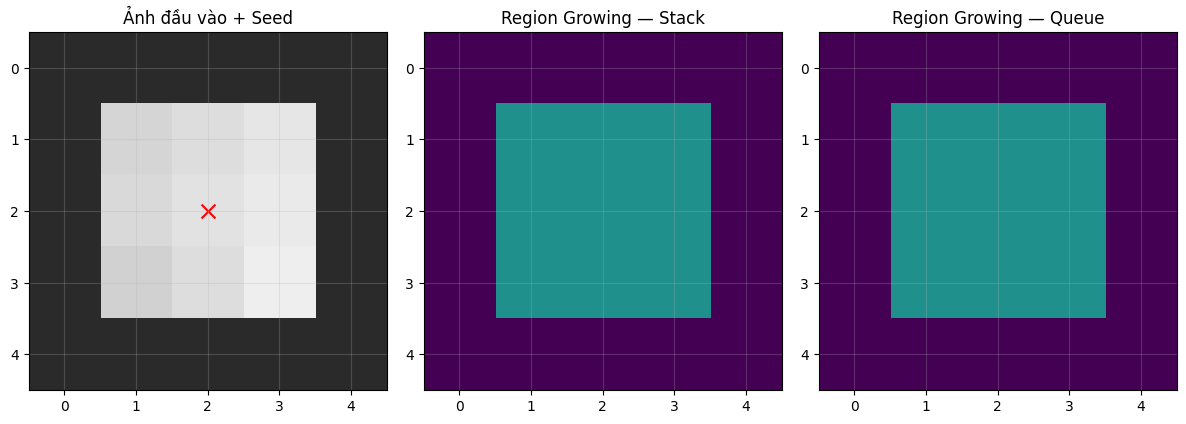

In [ ]:
# Kiểm chứng Region Growing với ảnh nhỏ

# Ảnh xám 5 × 5
img_test = np.array([
    [10, 10, 10, 10, 10],
    [10, 50, 52, 54, 10],
    [10, 51, 53, 55, 10],
    [10, 49, 52, 56, 10],
    [10, 10, 10, 10, 10]
], dtype=np.float64)

# Seed ở trung tâm
seeds_test = [(2, 2)]

# Ngưỡng chấp nhận
T_test = 5

labels_stack_test = region_growing_classic(
    img_test,
    seeds=seeds_test,
    T=T_test,
    order="stack"
)

labels_queue_test = region_growing_classic(
    img_test,
    seeds=seeds_test,
    T=T_test,
    order="queue"
)

print("=== ẢNH ĐẦU VÀO ===")
print(img_test)

print("\n=== REGION GROWING — STACK ===")
print(labels_stack_test)

print("\n=== REGION GROWING — QUEUE ===")
print(labels_queue_test)

assert labels_stack_test.shape == img_test.shape
assert labels_queue_test.shape == img_test.shape

assert labels_stack_test.dtype == np.int32
assert labels_queue_test.dtype == np.int32

assert labels_stack_test[2, 2] == 0
assert labels_queue_test[2, 2] == 0

# Nền mức xám 10 không thuộc vùng có mức xám khoảng 50
assert labels_stack_test[0, 0] == -1
assert labels_queue_test[0, 0] == -1

# Tất cả 9 pixel ở khối giữa thuộc vùng 0
assert np.all(labels_stack_test[1:4, 1:4] == 0)
assert np.all(labels_queue_test[1:4, 1:4] == 0)

different_pixels_test = np.count_nonzero(
    labels_stack_test != labels_queue_test
)

print("\n=== KẾT QUẢ KIỂM CHỨNG ===")
print("PASS: Kích thước output đúng.")
print("PASS: Kiểu dữ liệu int32.")
print("PASS: Seed được gán nhãn 0.")
print("PASS: Pixel nền giữ nhãn -1.")
print("PASS: Vùng trung tâm được mở rộng đúng.")
print("Số pixel khác nhãn:", different_pixels_test)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(img_test, cmap="gray", vmin=0, vmax=60)
axes[0].scatter([2], [2], c="red", marker="x", s=100)
axes[0].set_title("Ảnh đầu vào + Seed")

axes[1].imshow(
    labels_stack_test,
    cmap="viridis",
    vmin=-1,
    vmax=1
)
axes[1].set_title("Region Growing — Stack")

axes[2].imshow(
    labels_queue_test,
    cmap="viridis",
    vmin=-1,
    vmax=1
)
axes[2].set_title("Region Growing — Queue")

for ax in axes:
    ax.set_xticks(range(5))
    ax.set_yticks(range(5))
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 5. Kiểm chứng B4 — So sánh Stack và Queue

### 5.1. Chuẩn bị ảnh Gradient

Thí nghiệm sử dụng ảnh xám tổng hợp có kích thước 64 × 64 pixel.

Ảnh được tạo bằng sự kết hợp giữa:
- Gradient theo chiều ngang.
- Gradient theo chiều dọc.
- Biến thiên cường độ dạng sóng.
- Nhiễu Gaussian nhẹ có seed cố định để tái lập kết quả.

**Mục đích:**

Khảo sát ảnh hưởng của thứ tự duyệt Stack (LIFO) và Queue (FIFO) đến kết quả Region Growing cổ điển.

Do trung bình vùng được cập nhật sau mỗi pixel được chấp nhận, thứ tự duyệt có thể dẫn đến các kết quả phân vùng khác nhau.

**Thiết lập:**
- Kích thước ảnh: 64 × 64.
- Kết nối: 4 hướng.
- Ngưỡng T: 14.
- Sử dụng cùng ảnh và seed cho cả Stack và Queue.

**Prompt hỗ trợ AI cho phần thí nghiệm:**

> Hãy hỗ trợ tạo một ảnh gradient xám tổng hợp 64 × 64 bằng gradient ngang, gradient dọc, thành phần sin/cos và nhiễu Gaussian có random seed cố định. Chuẩn bị seed và ngưỡng dùng chung cho thí nghiệm so sánh Region Growing theo stack và queue; trực quan hóa ảnh đầu vào.

=== CHUẨN BỊ THÍ NGHIỆM B4 ===
Kích thước ảnh: (64, 64)
Kiểu dữ liệu: float64
Mức xám nhỏ nhất: 67.75
Mức xám lớn nhất: 160.75
Seeds: [(32, 32)]
Ngưỡng T: 14


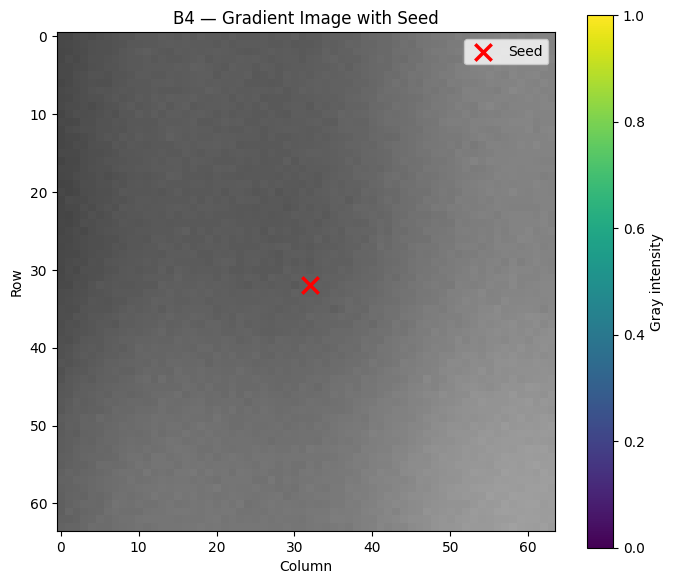

In [ ]:
height, width = 64, 64

rows, cols = np.mgrid[0:height, 0:width]

gradient_horizontal = 0.9 * cols
gradient_vertical = 0.45 * rows

wave = (
    8 * np.sin(cols / 7.0)
    + 6 * np.cos(rows / 9.0)
)

rng = np.random.default_rng(seed=42)

noise = rng.normal(
    loc=0,
    scale=1.5,
    size=(height, width)
)

gradient_img = (
    65
    + gradient_horizontal
    + gradient_vertical
    + wave
    + noise
)

# Giữ giá trị mức xám trong khoảng [0, 255]
gradient_img = np.clip(
    gradient_img,
    0,
    255
).astype(np.float64)

gradient_seeds = [
    (32, 32)
]

T_gradient = 14

print("=== CHUẨN BỊ THÍ NGHIỆM B4 ===")
print("Kích thước ảnh:", gradient_img.shape)
print("Kiểu dữ liệu:", gradient_img.dtype)
print("Mức xám nhỏ nhất:", round(gradient_img.min(), 2))
print("Mức xám lớn nhất:", round(gradient_img.max(), 2))
print("Seeds:", gradient_seeds)
print("Ngưỡng T:", T_gradient)

plt.figure(figsize=(7, 6))

plt.imshow(
    gradient_img,
    cmap="gray",
    vmin=0,
    vmax=255
)

for row, col in gradient_seeds:
    plt.scatter(
        col,
        row,
        c="red",
        marker="x",
        s=140,
        linewidths=2.5,
        label="Seed"
    )

plt.title("B4 — Gradient Image with Seed")
plt.xlabel("Column")
plt.ylabel("Row")
plt.legend()
plt.colorbar(label="Gray intensity")
plt.tight_layout()
plt.show()


### 5.2. B4 — So sánh kết quả Region Growing giữa Stack và Queue

Thực hiện Region Growing cổ điển trên cùng ảnh gradient với:
- Cùng seed tại `(32, 32)`.
- Cùng ngưỡng `T = 14`.
- Cùng kết nối 4 hướng.
- Chỉ thay đổi thứ tự xử lý: Stack (LIFO) hoặc Queue (FIFO).

Số pixel khác nhãn được xác định bằng:

$$
D = \sum_{r,c}
\mathbf{1}\left[
L_{\text{stack}}(r,c)
\neq L_{\text{queue}}(r,c)
\right]
$$

Trong đó:
- $L_{\text{stack}}$: Bản đồ nhãn từ Stack.
- $L_{\text{queue}}$: Bản đồ nhãn từ Queue.
- $D$: Tổng số pixel có nhãn khác nhau.

Mục đích là đánh giá ảnh hưởng của thứ tự duyệt đến kết quả phân vùng khi trung bình vùng được cập nhật liên tục

**Prompt hỗ trợ AI cho phần thí nghiệm:**

> Hãy hỗ trợ thiết kế phép so sánh Region Growing stack (LIFO) và queue (FIFO) trên cùng ảnh gradient 64 × 64, seed (32, 32), T = 14 và kết nối 4 hướng. Kiểm tra output và đếm số pixel có nhãn khác nhau; trình bày bản đồ nhãn và bản đồ sai khác.

=== B4: STACK VS QUEUE ===
Kích thước ảnh: (64, 64)
Seeds: [(32, 32)]
Ngưỡng T: 14

=== SỐ PIXEL THUỘC VÙNG ===
Stack: 1802
Queue: 2003

=== KHÁC BIỆT BẢN ĐỒ NHÃN ===
Tổng số pixel: 4096
Số pixel khác nhãn: 1463
Tỷ lệ khác nhãn: 35.72%


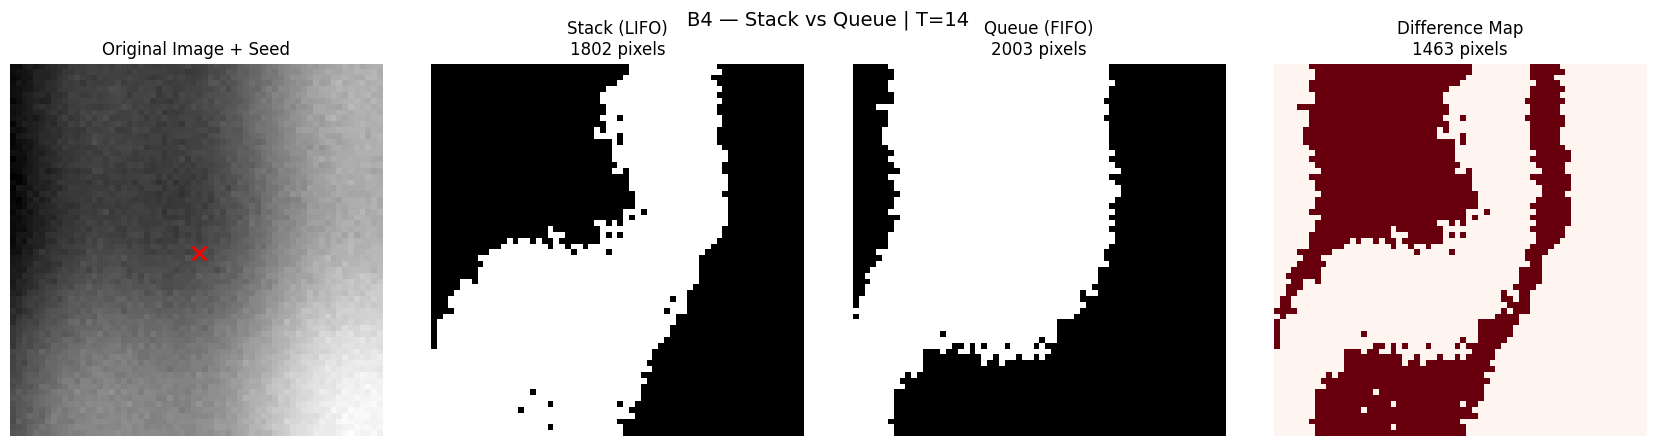


PASS: Đã so sánh Stack và Queue thành công.


In [ ]:
# B4: So sánh Stack và Queue

labels_stack = region_growing_classic(
    gradient_img,
    seeds=gradient_seeds,
    T=T_gradient,
    order="stack"
)

labels_queue = region_growing_classic(
    gradient_img,
    seeds=gradient_seeds,
    T=T_gradient,
    order="queue"
)

assert labels_stack.shape == gradient_img.shape
assert labels_queue.shape == gradient_img.shape

assert labels_stack.dtype == np.int32
assert labels_queue.dtype == np.int32

difference_mask = labels_stack != labels_queue

different_pixels = int(np.count_nonzero(difference_mask))
total_pixels = gradient_img.size

difference_percent = (
    different_pixels / total_pixels * 100
)

stack_region_pixels = int(
    np.count_nonzero(labels_stack == 0)
)

queue_region_pixels = int(
    np.count_nonzero(labels_queue == 0)
)

print("=== B4: STACK VS QUEUE ===")
print("Kích thước ảnh:", gradient_img.shape)
print("Seeds:", gradient_seeds)
print("Ngưỡng T:", T_gradient)

print("\n=== SỐ PIXEL THUỘC VÙNG ===")
print("Stack:", stack_region_pixels)
print("Queue:", queue_region_pixels)

print("\n=== KHÁC BIỆT BẢN ĐỒ NHÃN ===")
print("Tổng số pixel:", total_pixels)
print("Số pixel khác nhãn:", different_pixels)
print(f"Tỷ lệ khác nhãn: {difference_percent:.2f}%")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))

# Ảnh gốc
axes[0].imshow(gradient_img, cmap="gray")

for row, col in gradient_seeds:
    axes[0].scatter(
        col, row,
        c="red",
        marker="x",
        s=100,
        linewidths=2
    )

axes[0].set_title("Original Image + Seed")

# Stack: 0 là vùng được chọn, -1 là chưa gán
axes[1].imshow(
    labels_stack == 0,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[1].set_title(
    f"Stack (LIFO)\n{stack_region_pixels} pixels"
)

# Queue
axes[2].imshow(
    labels_queue == 0,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[2].set_title(
    f"Queue (FIFO)\n{queue_region_pixels} pixels"
)

# Bản đồ khác biệt
axes[3].imshow(
    difference_mask,
    cmap="Reds",
    vmin=0,
    vmax=1
)
axes[3].set_title(
    f"Difference Map\n{different_pixels} pixels"
)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"B4 — Stack vs Queue | T={T_gradient}",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("\nPASS: Đã so sánh Stack và Queue thành công.")


### 5.3. B4 — Khảo sát ảnh hưởng của ngưỡng T

Thí nghiệm giữ nguyên ảnh gradient, vị trí seed và kết nối 4 hướng, chỉ thay đổi ngưỡng chấp nhận pixel.

Các giá trị được khảo sát:

`T = [2, 5, 8, 11, 14, 17, 20, 25, 30]`

Với mỗi giá trị T:
1. Chạy Region Growing bằng Stack.
2. Chạy Region Growing bằng Queue.
3. Đếm số pixel được gán vào vùng.
4. Đếm số pixel có nhãn khác nhau giữa hai kết quả.

Điều kiện chấp nhận pixel:

$$
|I(q)-\mu_R| \leq T
$$

Ngưỡng T càng lớn thì điều kiện chấp nhận pixel càng ít nghiêm ngặt. Tuy nhiên, do trung bình vùng thay đổi theo quá trình mở rộng, số pixel được chọn không nhất thiết tăng đơn điệu trong mọi trường hợp.

**Prompt hỗ trợ AI cho phần thí nghiệm:**

> Hãy hỗ trợ khảo sát các ngưỡng T = [2, 5, 8, 11, 14, 17, 20, 25, 30] đối với Region Growing theo stack và queue. Giữ nguyên ảnh và seed, đếm số pixel thuộc vùng của mỗi cách duyệt, đếm số pixel khác nhãn, tính tỷ lệ phần trăm và vẽ đồ thị so sánh.

=== B4: KHẢO SÁT NGƯỠNG T ===
Kích thước ảnh: (64, 64)
Seeds: [(32, 32)]

   T |   Stack |   Queue |  Khác nhãn |  Tỷ lệ (%)
------------------------------------------------------
   2 |     171 |     155 |         76 |       1.86
   5 |     608 |    1082 |       1000 |      24.41
   8 |    1475 |    1436 |        107 |       2.61
  11 |    1942 |    1716 |        420 |      10.25
  14 |    1802 |    2003 |       1463 |      35.72
  17 |    2612 |    2304 |        848 |      20.70
  20 |    2848 |    2673 |        319 |       7.79
  25 |    3388 |    3001 |        619 |      15.11
  30 |    3650 |    3529 |        227 |       5.54

PASS: Kết quả T=14 khớp với Cell 14.


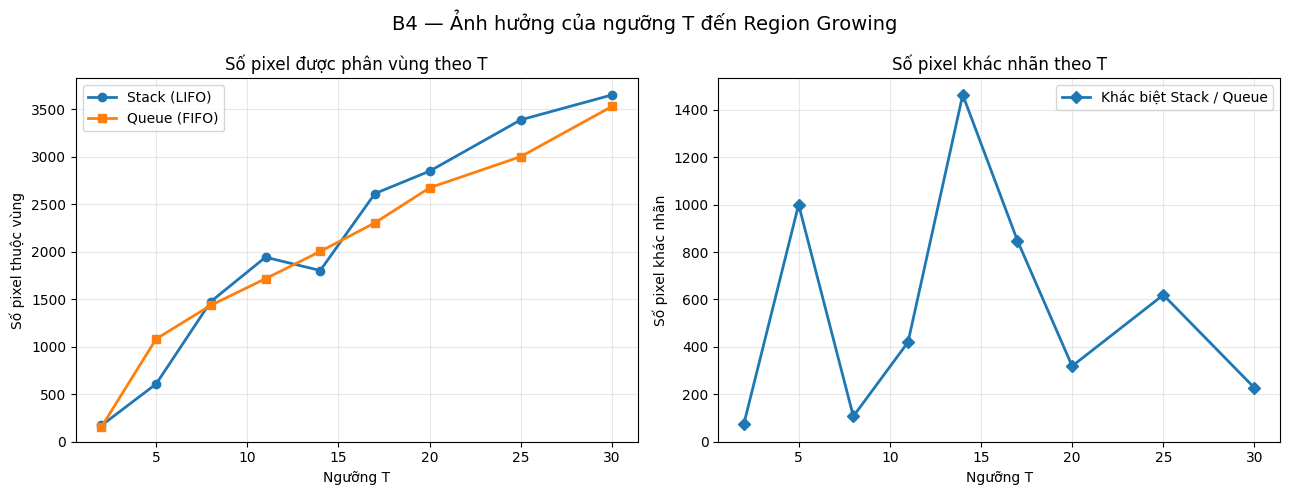

In [ ]:
# Khảo sát ảnh hưởng của ngưỡng T

T_values = [2, 5, 8, 11, 14, 17, 20, 25, 30]

stack_counts = []
queue_counts = []
difference_counts = []
difference_percents = []

total_pixels = gradient_img.size

for T in T_values:

    result_stack = region_growing_classic(
        gradient_img,
        seeds=gradient_seeds,
        T=T,
        order="stack"
    )

    result_queue = region_growing_classic(
        gradient_img,
        seeds=gradient_seeds,
        T=T,
        order="queue"
    )

    # Vì thí nghiệm chỉ có một seed nên vùng mang nhãn 0
    n_stack = int(np.count_nonzero(result_stack == 0))
    n_queue = int(np.count_nonzero(result_queue == 0))

    n_different = int(
        np.count_nonzero(result_stack != result_queue)
    )

    pct_different = n_different / total_pixels * 100

    stack_counts.append(n_stack)
    queue_counts.append(n_queue)
    difference_counts.append(n_different)
    difference_percents.append(pct_different)

print("=== B4: KHẢO SÁT NGƯỠNG T ===")
print(f"Kích thước ảnh: {gradient_img.shape}")
print(f"Seeds: {gradient_seeds}")
print()

print(
    f"{'T':>4} | {'Stack':>7} | {'Queue':>7} | "
    f"{'Khác nhãn':>10} | {'Tỷ lệ (%)':>10}"
)
print("-" * 54)

for i, T in enumerate(T_values):
    print(
        f"{T:>4} | "
        f"{stack_counts[i]:>7} | "
        f"{queue_counts[i]:>7} | "
        f"{difference_counts[i]:>10} | "
        f"{difference_percents[i]:>10.2f}"
    )

index_t14 = T_values.index(T_gradient)

assert stack_counts[index_t14] == stack_region_pixels
assert queue_counts[index_t14] == queue_region_pixels
assert difference_counts[index_t14] == different_pixels

print("\nPASS: Kết quả T=14 khớp với Cell 14.")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ 1: Số pixel được phân vùng
axes[0].plot(
    T_values,
    stack_counts,
    marker="o",
    linewidth=2,
    label="Stack (LIFO)"
)

axes[0].plot(
    T_values,
    queue_counts,
    marker="s",
    linewidth=2,
    label="Queue (FIFO)"
)

axes[0].set_title("Số pixel được phân vùng theo T")
axes[0].set_xlabel("Ngưỡng T")
axes[0].set_ylabel("Số pixel thuộc vùng")
axes[0].set_ylim(bottom=0)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Biểu đồ 2: Số pixel khác nhãn
axes[1].plot(
    T_values,
    difference_counts,
    marker="D",
    linewidth=2,
    label="Khác biệt Stack / Queue"
)

axes[1].set_title("Số pixel khác nhãn theo T")
axes[1].set_xlabel("Ngưỡng T")
axes[1].set_ylabel("Số pixel khác nhãn")
axes[1].set_ylim(bottom=0)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.suptitle(
    "B4 — Ảnh hưởng của ngưỡng T đến Region Growing",
    fontsize=14
)

plt.tight_layout()
plt.show()


### 5.4. Kiểm chứng Region Growing với nhiều Seed

Thí nghiệm sử dụng ảnh xám tổng hợp có ba vùng với cường độ khác nhau.

Các seed được đặt tại:
- Vùng 0: `(2, 2)`
- Vùng 1: `(2, 7)`
- Vùng 2: `(7, 5)`

**Mục tiêu kiểm chứng:**

1. Mỗi seed được gán đúng nhãn tương ứng.
2. Các vùng được mở rộng dựa trên ngưỡng T.
3. Pixel không thuộc vùng nào giữ nhãn `-1`.
4. Các vùng không ghi đè nhãn lên nhau.
5. Kết quả có kiểu dữ liệu `int32`.
6. So sánh kết quả khi sử dụng Stack và Queue.

**Prompt hỗ trợ AI cho phần thí nghiệm:**

> Hãy hỗ trợ thiết kế kiểm chứng Region Growing nhiều seed trên ảnh xám 10 × 10 có ba vùng mức xám 50, 120 và 200, với seed tại (2, 2), (2, 7), (7, 5) và T = 5. Đối chiếu stack/queue, bảo đảm nhãn của seed không bị ghi đè, pixel chưa gán mang nhãn -1 và kết quả là int32.

=== REGION GROWING — MULTI-SEED ===
Ảnh đầu vào:
[[  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]
 [  0.  50.  50.  50.   0.   0. 120. 120. 120.   0.]
 [  0.  50.  50.  50.   0.   0. 120. 120. 120.   0.]
 [  0.  50.  50.  50.   0.   0. 120. 120. 120.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]
 [  0.   0.   0. 200. 200. 200. 200. 200.   0.   0.]
 [  0.   0.   0. 200. 200. 200. 200. 200.   0.   0.]
 [  0.   0.   0. 200. 200. 200. 200. 200.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]]

Bản đồ nhãn Stack:
[[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
 [-1  0  0  0 -1 -1  1  1  1 -1]
 [-1  0  0  0 -1 -1  1  1  1 -1]
 [-1  0  0  0 -1 -1  1  1  1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1  2  2  2  2  2 -1 -1]
 [-1 -1 -1  2  2  2  2  2 -1 -1]
 [-1 -1 -1  2  2  2  2  2 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1]]

Bản đồ nhãn Queue:
[[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
 [-1  0  0  0 -1

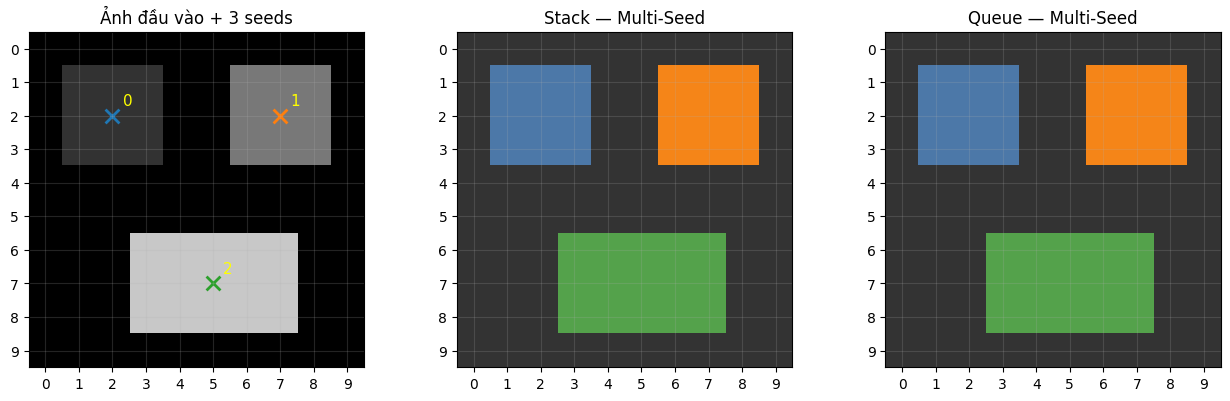

In [ ]:
# Kiểm chứng Region Growing với nhiều Seed

multi_img = np.zeros((10, 10), dtype=np.float64)

# Ba vùng có mức xám khác nhau
multi_img[1:4, 1:4] = 50
multi_img[1:4, 6:9] = 120
multi_img[6:9, 3:8] = 200

multi_seeds = [
    (2, 2),  # Vùng 0, mức xám 50
    (2, 7),  # Vùng 1, mức xám 120
    (7, 5)   # Vùng 2, mức xám 200
]

T_multi = 5

multi_labels_stack = region_growing_classic(
    multi_img,
    seeds=multi_seeds,
    T=T_multi,
    order="stack"
)

multi_labels_queue = region_growing_classic(
    multi_img,
    seeds=multi_seeds,
    T=T_multi,
    order="queue"
)

assert multi_labels_stack.shape == multi_img.shape
assert multi_labels_queue.shape == multi_img.shape

assert multi_labels_stack.dtype == np.int32
assert multi_labels_queue.dtype == np.int32

for label_id, (row, col) in enumerate(multi_seeds):
    assert multi_labels_stack[row, col] == label_id
    assert multi_labels_queue[row, col] == label_id

expected_multi = np.full(
    multi_img.shape,
    -1,
    dtype=np.int32
)

expected_multi[1:4, 1:4] = 0
expected_multi[1:4, 6:9] = 1
expected_multi[6:9, 3:8] = 2

assert np.array_equal(
    multi_labels_stack,
    expected_multi
), "Stack chưa tạo đúng bản đồ nhãn mong đợi"

assert np.array_equal(
    multi_labels_queue,
    expected_multi
), "Queue chưa tạo đúng bản đồ nhãn mong đợi"

print("=== REGION GROWING — MULTI-SEED ===")
print("Ảnh đầu vào:")
print(multi_img)

print("\nBản đồ nhãn Stack:")
print(multi_labels_stack)

print("\nBản đồ nhãn Queue:")
print(multi_labels_queue)

print("\n=== THỐNG KÊ ===")

for label_id in range(len(multi_seeds)):
    count_stack = np.count_nonzero(
        multi_labels_stack == label_id
    )

    count_queue = np.count_nonzero(
        multi_labels_queue == label_id
    )

    print(
        f"Vùng {label_id}: "
        f"Stack={count_stack}, Queue={count_queue}"
    )

unassigned = np.count_nonzero(
    multi_labels_stack == -1
)

different = np.count_nonzero(
    multi_labels_stack != multi_labels_queue
)

print("Pixel chưa gán nhãn:", unassigned)
print("Pixel khác nhãn:", different)

print("\nPASS: Cả ba seed giữ đúng nhãn.")
print("PASS: Stack và Queue tạo đúng ba vùng.")
print("PASS: Không có pixel bị ghi đè sai nhãn.")
print("PASS: Output có dtype int32.")

from matplotlib.colors import ListedColormap, BoundaryNorm

label_cmap = ListedColormap([
    "#333333",  # -1: chưa gán
    "#4C78A8",  # 0
    "#F58518",  # 1
    "#54A24B"   # 2
])

label_norm = BoundaryNorm(
    [-1.5, -0.5, 0.5, 1.5, 2.5],
    label_cmap.N
)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(multi_img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Ảnh đầu vào + 3 seeds")

for label_id, (row, col) in enumerate(multi_seeds):
    axes[0].scatter(
        col, row,
        marker="x",
        s=100,
        linewidths=2
    )
    axes[0].text(
        col + 0.3,
        row - 0.3,
        str(label_id),
        color="yellow",
        fontsize=11
    )

axes[1].imshow(
    multi_labels_stack,
    cmap=label_cmap,
    norm=label_norm
)
axes[1].set_title("Stack — Multi-Seed")

axes[2].imshow(
    multi_labels_queue,
    cmap=label_cmap,
    norm=label_norm
)
axes[2].set_title("Queue — Multi-Seed")

for ax in axes:
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()



### 5.5. Kiểm chứng các trường hợp biên của Region Growing

Thực hiện kiểm thử hàm `region_growing_classic()` với các trường hợp:

1. Seed nằm ngoài phạm vi ảnh.
2. Danh sách seed có tọa độ trùng nhau.
3. Ngưỡng T âm.
4. Ngưỡng T không hữu hạn.
5. Giá trị `order` không hợp lệ.
6. Ảnh đầu vào không phải ảnh xám hai chiều.
7. Danh sách seed rỗng.
8. Ngưỡng T bằng 0.
9. Ảnh có kích thước 1 × 1.
10. Ảnh chứa giá trị không hữu hạn.

**Tiêu chí:** Hàm phải trả về kết quả hợp lệ hoặc phát sinh `ValueError` rõ ràng theo quy ước đã thiết kế.

**Prompt hỗ trợ AI cho phần thí nghiệm:**

> Hãy hỗ trợ bổ sung các kiểm thử biên cho hàm Region Growing đã có: seed ngoài ảnh, seed trùng, T âm hoặc không hữu hạn, order không hợp lệ, ảnh không phải grayscale, seed rỗng, T = 0, ảnh 1 × 1 và ảnh có giá trị không hữu hạn. Kiểm tra lỗi mong đợi bằng assert hoặc try/except, không sửa hàm cài đặt.

In [ ]:
# Kiểm chứng các trường hợp biên Region Growing

import numpy as np

# Ảnh kiểm thử cơ bản
edge_img = np.array([
    [10, 10, 50],
    [10, 12, 50],
    [80, 80, 90]
], dtype=np.float64)

def expect_value_error(test_name, test_function):
    """Kiểm tra lời gọi có phát sinh ValueError hay không."""
    try:
        test_function()
    except ValueError:
        print(f"PASS: {test_name}")
    else:
        raise AssertionError(
            f"FAIL: {test_name} không phát sinh ValueError"
        )

# TEST 1 — Seed ngoài phạm vi ảnh

expect_value_error(
    "Seed ngoài phạm vi ảnh",
    lambda: region_growing_classic(
        edge_img,
        seeds=[(10, 10)],
        T=5
    )
)

# TEST 2 — Seed trùng nhau

expect_value_error(
    "Seed trùng nhau",
    lambda: region_growing_classic(
        edge_img,
        seeds=[(1, 1), (1, 1)],
        T=5
    )
)

# TEST 3 — Ngưỡng T âm

expect_value_error(
    "Ngưỡng T âm",
    lambda: region_growing_classic(
        edge_img,
        seeds=[(1, 1)],
        T=-1
    )
)

# TEST 4 — Ngưỡng T không hữu hạn

expect_value_error(
    "Ngưỡng T bằng vô hạn",
    lambda: region_growing_classic(
        edge_img,
        seeds=[(1, 1)],
        T=np.inf
    )
)

# TEST 5 — order không hợp lệ

expect_value_error(
    "Giá trị order không hợp lệ",
    lambda: region_growing_classic(
        edge_img,
        seeds=[(1, 1)],
        T=5,
        order="random"
    )
)

# TEST 6 — Ảnh đầu vào không phải 2D

expect_value_error(
    "Ảnh đầu vào không phải ảnh xám 2D",
    lambda: region_growing_classic(
        np.zeros((3, 3, 3)),
        seeds=[(1, 1)],
        T=5
    )
)

# TEST 7 — Danh sách seed rỗng

empty_seed_labels = region_growing_classic(
    edge_img,
    seeds=[],
    T=5
)

assert empty_seed_labels.shape == edge_img.shape
assert empty_seed_labels.dtype == np.int32
assert np.all(empty_seed_labels == -1)

print("PASS: Seed rỗng trả về toàn bộ nhãn -1.")

# TEST 8 — Ngưỡng T bằng 0

zero_t_labels = region_growing_classic(
    edge_img,
    seeds=[(0, 0)],
    T=0,
    order="queue"
)

# Ba pixel có mức xám 10 kết nối với seed
assert np.count_nonzero(zero_t_labels == 0) == 3
assert zero_t_labels[0, 0] == 0
assert zero_t_labels[0, 1] == 0
assert zero_t_labels[1, 0] == 0

# Pixel khác mức xám không được nhận vào vùng
assert zero_t_labels[1, 1] == -1

print("PASS: T=0 chỉ nhận các pixel có cùng mức xám.")

# TEST 9 — Ảnh kích thước 1 × 1

single_img = np.array([[42]], dtype=np.float64)

single_labels = region_growing_classic(
    single_img,
    seeds=[(0, 0)],
    T=0,
    order="stack"
)

assert single_labels.shape == (1, 1)
assert single_labels.dtype == np.int32
assert single_labels[0, 0] == 0

print("PASS: Ảnh 1 × 1 được xử lý đúng.")

# TEST 10 — Ảnh có NaN

nan_img = edge_img.copy()
nan_img[0, 0] = np.nan

expect_value_error(
    "Ảnh chứa NaN",
    lambda: region_growing_classic(
        nan_img,
        seeds=[(1, 1)],
        T=5
    )
)

# TỔNG KẾT

print("\n=== TỔNG KẾT CELL 17 ===")
print("PASS: 10/10 trường hợp kiểm chứng.")
print("Region Growing xử lý đúng các trường hợp đã thử.")


PASS: Seed ngoài phạm vi ảnh
PASS: Seed trùng nhau
PASS: Ngưỡng T âm
PASS: Ngưỡng T bằng vô hạn
PASS: Giá trị order không hợp lệ
PASS: Ảnh đầu vào không phải ảnh xám 2D
PASS: Seed rỗng trả về toàn bộ nhãn -1.
PASS: T=0 chỉ nhận các pixel có cùng mức xám.
PASS: Ảnh 1 × 1 được xử lý đúng.
PASS: Ảnh chứa NaN

=== TỔNG KẾT CELL 17 ===
PASS: 10/10 trường hợp kiểm chứng.
Region Growing xử lý đúng các trường hợp đã thử.


## 6. Tổng kết Region Growing cổ điển và kiểm chứng B4

### 6.1. Nội dung đã thực hiện

Đã cài đặt hàm:

`region_growing_classic(img, seeds, T, order="stack")`

Thuật toán sử dụng:
- Ảnh xám hai chiều.
- Một hoặc nhiều seed có tọa độ `(row, col)`.
- Kết nối 4 hướng: trên, dưới, trái, phải.
- Ngưỡng chấp nhận pixel T.
- Trung bình mức xám của vùng được cập nhật sau mỗi pixel được chấp nhận.
- Hai chế độ duyệt Stack (LIFO) và Queue (FIFO).

Kết quả trả về là mảng nhãn `int32` có cùng kích thước với ảnh, trong đó:
- `0, 1, 2, ...`: Nhãn các vùng tương ứng với thứ tự seed.
- `-1`: Pixel chưa được phân vùng.

### 6.2. Điều kiện phát triển vùng

Pixel ứng viên q được chấp nhận khi:

$$
|I(q)-\mu_R|\leq T
$$

Trong đó:
- $I(q)$ là giá trị mức xám của pixel ứng viên.
- $\mu_R$ là giá trị mức xám trung bình hiện tại của vùng.
- $T$ là ngưỡng chấp nhận pixel.

Khi thêm pixel mới, tổng cường độ và số lượng pixel thuộc vùng được cập nhật để tính lại trung bình vùng.

### 6.3. So sánh Stack và Queue

**Stack (LIFO):**
- Pixel được thêm sau được xử lý trước.
- Có xu hướng mở rộng sâu theo một hướng.

**Queue (FIFO):**
- Pixel được thêm trước được xử lý trước.
- Có xu hướng mở rộng theo từng lớp từ seed.

Sự khác biệt về thứ tự duyệt có thể làm thay đổi trình tự cập nhật trung bình vùng.

Do đó, hai phương pháp có thể tạo ra bản đồ nhãn khác nhau dù sử dụng cùng ảnh, cùng seed và cùng ngưỡng T.

### 6.4. Kết quả kiểm chứng

**Kiểm chứng trên ảnh 5 × 5 (Cell 12):**

- Cả Stack và Queue đều phân vùng đúng khối trung tâm.
- Pixel nền không phù hợp giữ nhãn `-1`.
- Hai phương pháp cho cùng bản đồ nhãn trong trường hợp này.

**Kiểm chứng B4 trên ảnh gradient 64 × 64 (Cell 13–14):**

- Sử dụng cùng ảnh gradient.
- Seed tại `(32, 32)`.
- Ngưỡng `T = 14`.
- So sánh bản đồ nhãn từ Stack và Queue.
- Đánh giá mức độ khác biệt bằng số pixel có nhãn khác nhau.

Công thức:

$$
D=\sum_{r,c}
\mathbf{1}
[L_{\mathrm{stack}}(r,c)\neq L_{\mathrm{queue}}(r,c)]
$$

Giá trị D thực tế được in trong Cell 14.

**Khảo sát ngưỡng T (Cell 15):**

- Thử các giá trị T từ 2 đến 30.
- Đếm số pixel được phân vùng bằng Stack và Queue.
- Đếm số pixel khác nhãn tương ứng với từng T.
- Trực quan hóa kết quả bằng hai biểu đồ.

**Kiểm chứng nhiều seed (Cell 16):**

- Sử dụng ba seed.
- Ba vùng được gán nhãn 0, 1 và 2.
- Kiểm tra việc bảo toàn nhãn seed.
- Kiểm tra các pixel chưa phân vùng giữ nhãn `-1`.
- Stack và Queue cho cùng kết quả trên ảnh mẫu gồm ba vùng đồng nhất.

**Kiểm chứng trường hợp biên (Cell 17):**

Đã kiểm thử 10 trường hợp, bao gồm:
- Seed ngoài ảnh.
- Seed trùng nhau.
- Ngưỡng T không hợp lệ.
- Chế độ order không hợp lệ.
- Ảnh đầu vào sai số chiều.
- Danh sách seed rỗng.
- Ngưỡng T bằng 0.
- Ảnh 1 × 1.
- Ảnh chứa NaN.

Các kiểm chứng trên dữ liệu mẫu đã chạy thành công.

### 6.5. Nhận xét và kết luận

Region Growing cổ điển phát triển vùng từ seed bằng cách chấp nhận những pixel lân cận có cường độ phù hợp với trung bình vùng hiện tại.

Các kết quả cho thấy:

1. Khi mức xám giữa vùng và nền khác biệt rõ rệt, Stack và Queue có thể tạo ra cùng kết quả.
2. Trên ảnh có biến thiên mức xám, thứ tự duyệt có thể ảnh hưởng đến quá trình phát triển vùng.
3. Ngưỡng T ảnh hưởng trực tiếp đến điều kiện chấp nhận pixel và kết quả phân vùng.
4. Việc gán nhãn tất cả seed trước khi mở rộng giúp bảo vệ vị trí khởi tạo của từng vùng.

Số liệu thực nghiệm trong các cell trước là cơ sở để đánh giá mức độ khác biệt giữa hai phương pháp.

### 6.6. Giới hạn của phương pháp

- Kết quả phụ thuộc vào vị trí seed.
- Ngưỡng T cần được lựa chọn phù hợp với đặc điểm ảnh.
- Trung bình vùng phụ thuộc vào các pixel đã được chấp nhận trước đó.
- Với nhiều seed, thứ tự xử lý vùng có thể ảnh hưởng đến việc phân chia các pixel nằm giữa các vùng.
- Việc sử dụng Stack và Queue không bảo đảm tạo ra kết quả khác nhau trong mọi thí nghiệm.

---

## 7. Nội dung bàn giao cho nhóm

### 7.1. Bàn giao cho Người 5 — Seeded Region Growing

Hàm được cung cấp:

`region_growing_classic(img, seeds, T, order="stack")`

Quy ước đầu vào và đầu ra:
- `img`: Mảng ảnh xám `(H, W)`.
- `seeds`: Danh sách `(row, col)`.
- `T`: Ngưỡng sai khác mức xám.
- `order`: `"stack"` hoặc `"queue"`.
- Output: Mảng nhãn `(H, W)` có dtype `int32`.
- Pixel chưa phân vùng: `-1`.
- Nhãn vùng: Bắt đầu từ `0` theo thứ tự seed.

Hàm có thể được sử dụng làm đường cơ sở để so sánh với Seeded Region Growing của Người 5.

Cần thống nhất cách xử lý khi nhiều vùng cùng có khả năng nhận một pixel.

### 7.2. Bàn giao cho Tới — Tích hợp notebook

Các thành phần của Người 4:

**Phần A — ANMS**
- Hàm `anms(points, n_keep, c_robust=0.9)`.
- Kiểm chứng ANMS trên dữ liệu mẫu.
- Thí nghiệm A5: Top-N và ANMS.
- Chỉ số Grid Occupancy.
- Khảo sát hệ số `c_robust` và số lượng điểm N.

**Phần B — Region Growing**
- Hàm `region_growing_classic(img, seeds, T, order="stack")`.
- Kiểm chứng trên ảnh xám nhỏ.
- Thí nghiệm B4: Stack và Queue.
- Biểu đồ khảo sát ngưỡng T.
- Kiểm chứng nhiều seed và các trường hợp biên.

**Yêu cầu khi tích hợp:**
- Bảo đảm thứ tự chạy các cell.
- Tránh định nghĩa trùng các hàm dùng chung.
- Sử dụng đúng quy ước tọa độ `(row, col)`.
- Thống nhất kiểu dữ liệu và cách đánh nhãn.
- Giữ lại kết quả thực nghiệm và biểu đồ.
- Chạy lại toàn bộ notebook sau khi tích hợp.

### 7.3. Kết luận

Phần Người 4 đã triển khai hai nội dung chính:

1. **ANMS:** Chọn lọc điểm góc Harris dựa trên bán kính triệt tiêu nhằm cải thiện phân bố không gian so với cách chọn Top-N trong những trường hợp phù hợp.
2. **Region Growing cổ điển:** Phân vùng ảnh dựa trên seed và trung bình vùng, hỗ trợ hai cấu trúc xử lý Stack và Queue.

Các thí nghiệm A5 và B4 cung cấp hình ảnh, phép đo định lượng và dữ liệu để so sánh các phương pháp, phục vụ việc tích hợp vào bài tập nhóm.


## 8. Kiểm chứng tổng hợp trước khi bàn giao

Thực hiện kiểm chứng cuối cùng cho phần Người 4:

1. Xác nhận hàm ANMS chọn đúng điểm theo bán kính triệt tiêu.
2. Kiểm tra đầu ra ANMS có dạng `(N, 3)`.
3. Kiểm tra Top-N và ANMS sử dụng cùng số lượng điểm trong A5.
4. Xác nhận Grid Occupancy nằm trong khoảng 0–100%.
5. Kiểm tra bản đồ nhãn Region Growing có dtype `int32`.
6. Kiểm tra nhãn seed, nhãn `-1` và kích thước output.
7. Xác nhận số pixel khác nhãn của B4.
8. Kiểm tra thí nghiệm nhiều seed.

Kết quả kiểm chứng được tổng hợp thành bảng PASS/FAIL.

**Prompt hỗ trợ AI cho phần thí nghiệm:**

> Hãy hỗ trợ lập cell kiểm chứng tổng hợp cho ANMS và Region Growing từ các hàm đã được cài đặt. Kiểm tra hình dạng và giới hạn đầu ra, Grid Occupancy, kiểu int32 của nhãn, seed và nhãn -1, cùng chỉ số sai khác stack/queue. In PASS/FAIL và tổng số phép kiểm tra.

In [ ]:
# Kiểm chứng tổng hợp

import numpy as np

checks = []

def check_result(name, condition):
    """Ghi nhận kết quả kiểm chứng PASS hoặc FAIL."""
    passed = bool(condition)
    checks.append((name, passed))

    status = "PASS" if passed else "FAIL"
    print(f"[{status}] {name}")

print("=== KIỂM CHỨNG TỔNG HỢP NGƯỜI 4 ===\n")

# A. Kiểm chứng ANMS

test_points = np.array([
    [10, 10, 100],
    [12, 10, 95],
    [50, 50, 60],
    [90, 90, 40]
], dtype=float)

original_points = test_points.copy()

anms_result = anms(
    test_points,
    n_keep=3,
    c_robust=0.9
)

expected_anms = test_points[[0, 1, 3]]

check_result(
    "ANMS chọn đúng A, B, D",
    np.array_equal(anms_result, expected_anms)
)

check_result(
    "ANMS trả về kích thước (3, 3)",
    anms_result.shape == (3, 3)
)

check_result(
    "ANMS không thay đổi input",
    np.array_equal(test_points, original_points)
)

check_result(
    "ANMS xử lý n_keep=0",
    anms(test_points, 0).shape == (0, 3)
)

check_result(
    "ANMS xử lý n_keep lớn hơn số điểm",
    anms(test_points, 100).shape == (4, 3)
)

# B. Kiểm chứng A5

final_top = top_n(candidates, n_keep=keep)

final_anms = anms(
    candidates,
    n_keep=keep,
    c_robust=0.9
)

final_top_occupancy = grid_occupancy(
    final_top,
    scene.shape,
    grid_size=(8, 8)
)

final_anms_occupancy = grid_occupancy(
    final_anms,
    scene.shape,
    grid_size=(8, 8)
)

check_result(
    "A5: Top-N và ANMS giữ cùng số điểm",
    len(final_top) == len(final_anms)
)

check_result(
    "A5: Top-N Grid Occupancy hợp lệ",
    0 <= final_top_occupancy <= 100
)

check_result(
    "A5: ANMS Grid Occupancy hợp lệ",
    0 <= final_anms_occupancy <= 100
)

# C. Kiểm chứng Region Growing

final_stack = region_growing_classic(
    img_test,
    seeds=seeds_test,
    T=T_test,
    order="stack"
)

final_queue = region_growing_classic(
    img_test,
    seeds=seeds_test,
    T=T_test,
    order="queue"
)

check_result(
    "Region Growing: kích thước output đúng",
    final_stack.shape == img_test.shape
    and final_queue.shape == img_test.shape
)

check_result(
    "Region Growing: dtype int32",
    final_stack.dtype == np.int32
    and final_queue.dtype == np.int32
)

check_result(
    "Region Growing: seed giữ nhãn 0",
    final_stack[2, 2] == 0
    and final_queue[2, 2] == 0
)

check_result(
    "Region Growing: pixel nền giữ nhãn -1",
    final_stack[0, 0] == -1
    and final_queue[0, 0] == -1
)

# D. Kiểm chứng B4

b4_stack = region_growing_classic(
    gradient_img,
    seeds=gradient_seeds,
    T=T_gradient,
    order="stack"
)

b4_queue = region_growing_classic(
    gradient_img,
    seeds=gradient_seeds,
    T=T_gradient,
    order="queue"
)

b4_different = int(
    np.count_nonzero(b4_stack != b4_queue)
)

check_result(
    "B4: bản đồ nhãn cùng kích thước ảnh",
    b4_stack.shape == gradient_img.shape
    and b4_queue.shape == gradient_img.shape
)

check_result(
    "B4: số pixel khác nhãn khớp Cell 14",
    b4_different == different_pixels
)

# E. Kiểm chứng nhiều seed

final_multi = region_growing_classic(
    multi_img,
    seeds=multi_seeds,
    T=T_multi,
    order="queue"
)

seed_labels_correct = all(
    final_multi[row, col] == label_id
    for label_id, (row, col) in enumerate(multi_seeds)
)

check_result(
    "Multi-seed: mỗi seed giữ đúng nhãn",
    seed_labels_correct
)

check_result(
    "Multi-seed: bản đồ nhãn đúng kỳ vọng",
    np.array_equal(final_multi, expected_multi)
)

# F. Tổng kết

passed_count = sum(passed for _, passed in checks)
total_count = len(checks)
failed_count = total_count - passed_count

print("\n" + "=" * 48)
print("TỔNG KẾT KIỂM CHỨNG")
print("=" * 48)

print(f"Tổng số kiểm chứng: {total_count}")
print(f"PASS: {passed_count}")
print(f"FAIL: {failed_count}")

print("\n=== KẾT QUẢ A5 ===")
print(f"Top-N Grid Occupancy: {final_top_occupancy:.2f}%")
print(f"ANMS Grid Occupancy:  {final_anms_occupancy:.2f}%")

print("\n=== KẾT QUẢ B4 ===")
print(f"Stack vs Queue: {b4_different} pixel khác nhãn")

if failed_count == 0:
    print("\nALL CHECKS PASSED")
    print("Sẵn sàng chuyển sang bước bàn giao.")
else:
    print("\nCÓ KIỂM CHỨNG CHƯA ĐẠT")
    print("Cần xem lại kết quả trước khi bàn giao.")

    for name, passed in checks:
        if not passed:
            print("FAIL:", name)


=== KIỂM CHỨNG TỔNG HỢP NGƯỜI 4 ===

[PASS] ANMS chọn đúng A, B, D
[PASS] ANMS trả về kích thước (3, 3)
[PASS] ANMS không thay đổi input
[PASS] ANMS xử lý n_keep=0
[PASS] ANMS xử lý n_keep lớn hơn số điểm
[PASS] A5: Top-N và ANMS giữ cùng số điểm
[PASS] A5: Top-N Grid Occupancy hợp lệ
[PASS] A5: ANMS Grid Occupancy hợp lệ
[PASS] Region Growing: kích thước output đúng
[PASS] Region Growing: dtype int32
[PASS] Region Growing: seed giữ nhãn 0
[PASS] Region Growing: pixel nền giữ nhãn -1
[PASS] B4: bản đồ nhãn cùng kích thước ảnh
[PASS] B4: số pixel khác nhãn khớp Cell 14
[PASS] Multi-seed: mỗi seed giữ đúng nhãn
[PASS] Multi-seed: bản đồ nhãn đúng kỳ vọng

TỔNG KẾT KIỂM CHỨNG
Tổng số kiểm chứng: 16
PASS: 16
FAIL: 0

=== KẾT QUẢ A5 ===
Top-N Grid Occupancy: 20.31%
ANMS Grid Occupancy:  29.69%

=== KẾT QUẢ B4 ===
Stack vs Queue: 1463 pixel khác nhãn

ALL CHECKS PASSED
Sẵn sàng chuyển sang bước bàn giao.


# 9. Hoàn tất và bàn giao

## 9.1. Các nhiệm vụ đã thực hiện

### Phần A — ANMS

- [x] Cài đặt `anms(points, n_keep, c_robust=0.9)`.
- [x] Kiểm chứng công thức ANMS trên dữ liệu mẫu.
- [x] So sánh Top-N và ANMS trên cùng tập điểm Harris.
- [x] Tính Grid Occupancy.
- [x] Trực quan hóa kết quả A5.
- [x] Khảo sát hệ số `c_robust` và số lượng điểm N.

### Phần B — Region Growing cổ điển

- [x] Cài đặt `region_growing_classic(img, seeds, T, order="stack")`.
- [x] Hỗ trợ Stack (LIFO) và Queue (FIFO).
- [x] Sử dụng kết nối 4 hướng.
- [x] Cập nhật trung bình vùng sau khi chấp nhận pixel.
- [x] Trả về bản đồ nhãn `int32`, sử dụng `-1` cho pixel chưa phân vùng.
- [x] Kiểm chứng Region Growing trên ảnh nhỏ.
- [x] So sánh Stack và Queue trong thí nghiệm B4.
- [x] Khảo sát ảnh hưởng của ngưỡng T.
- [x] Kiểm chứng nhiều seed.
- [x] Kiểm thử các trường hợp biên.

## 9.2. Kết quả kiểm chứng

Cell 19 đã kiểm tra tổng hợp các chức năng chính và trả về:

**ALL CHECKS PASSED**

Các kết quả thực nghiệm được lưu trong notebook, bao gồm:
- Hình so sánh Top-N và ANMS.
- Grid Occupancy của hai phương pháp.
- Biểu đồ khảo sát `c_robust` và N.
- Bản đồ phân vùng Stack và Queue.
- Bản đồ pixel khác nhãn.
- Biểu đồ khảo sát ngưỡng T.

## 9.3. Giao diện các hàm bàn giao

**ANMS**

`anms(points, n_keep, c_robust=0.9)`

- Input: Mảng `(N, 3)` gồm `(row, col, response)`.
- Output: Mảng `(M, 3)` chứa các điểm được chọn theo bán kính giảm dần.

**Region Growing cổ điển**

`region_growing_classic(img, seeds, T, order="stack")`

- Input: Ảnh xám `(H, W)`, danh sách seed `(row, col)`, ngưỡng T và chế độ duyệt.
- Output: Bản đồ nhãn `(H, W)` có kiểu `int32`.
- Nhãn chưa phân vùng: `-1`.
- Nhãn các vùng: `0, 1, 2, ...`.

## 9.4. Lưu ý khi tích hợp

1. Không định nghĩa trùng các hàm Harris cổ điển của Người 2.
2. Giữ thống nhất quy ước tọa độ `(row, col)`.
3. Thống nhất định dạng seed và bản đồ nhãn với Người 5.
4. Chạy lại toàn bộ notebook sau khi tích hợp.
5. Giữ lại các output thực nghiệm và hình minh họa.
6. Xác nhận cách khai báo và phạm vi sử dụng AI theo quy định mới của giảng viên.

## 9.5. Kết luận

Phần Này đã hoàn thành hai thuật toán ANMS và Region Growing cổ điển, cùng các thí nghiệm kiểm chứng A5 và B4.

Kết quả cung cấp các hàm và dữ liệu thực nghiệm phục vụ việc so sánh thuật toán và tích hợp vào notebook cuối cùng của nhóm.

**Prompt hỗ trợ AI cho phần thí nghiệm:**

> Hãy hỗ trợ thiết kế thí nghiệm thay đổi c_robust trong [0.7, 0.8, 0.9, 0.95, 1.0] và số điểm N trong [10, 20, 30, 40, 60, 80] cho ANMS. Giữ cùng ảnh, cùng tập điểm Harris, đo Grid Occupancy trên lưới 8 × 8, vẽ đồ thị và xử lý trường hợp số ứng viên nhỏ hơn N.


=== ẢNH HƯỞNG CỦA c_robust ===
N cố định = 40
c_robust = 0.70 | Occupancy = 29.69%
c_robust = 0.80 | Occupancy = 29.69%
c_robust = 0.90 | Occupancy = 29.69%
c_robust = 0.95 | Occupancy = 34.38%
c_robust = 1.00 | Occupancy = 59.38%

=== ẢNH HƯỞNG CỦA N ===
N  | Top-N (%) | ANMS (%)
10 |      6.25 |     6.25
20 |      9.38 |    14.06
30 |     17.19 |    23.44
40 |     20.31 |    29.69
60 |     29.69 |    51.56
80 |     37.50 |    68.75


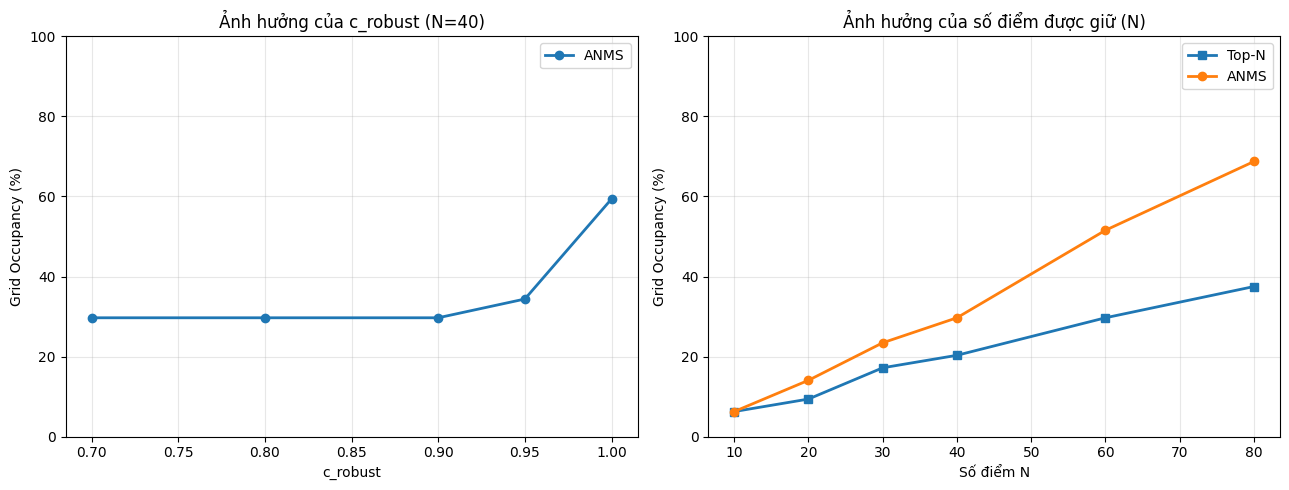

In [ ]:
# Khảo sát c_robust và số lượng điểm N

c_values = [0.7, 0.8, 0.9, 0.95, 1.0]
n_values = [10, 20, 30, 40, 60, 80]

# Không vượt quá số điểm Harris hiện có
n_values = [n for n in n_values if n <= len(candidates)]

grid_size = (8, 8)

# Thí nghiệm 1: Thay đổi c_robust, giữ cố định N

fixed_n = min(40, len(candidates))

occupancy_by_c = []

for c in c_values:
    selected = anms(
        candidates,
        n_keep=fixed_n,
        c_robust=c
    )

    occupancy = grid_occupancy(
        selected,
        scene.shape,
        grid_size=grid_size
    )

    occupancy_by_c.append(occupancy)

# Thí nghiệm 2: Thay đổi N, giữ c_robust = 0.9

occupancy_top_by_n = []
occupancy_anms_by_n = []

for n in n_values:

    selected_top = top_n(
        candidates,
        n_keep=n
    )

    selected_anms = anms(
        candidates,
        n_keep=n,
        c_robust=0.9
    )

    top_score = grid_occupancy(
        selected_top,
        scene.shape,
        grid_size=grid_size
    )

    anms_score = grid_occupancy(
        selected_anms,
        scene.shape,
        grid_size=grid_size
    )

    occupancy_top_by_n.append(top_score)
    occupancy_anms_by_n.append(anms_score)

print("=== ẢNH HƯỞNG CỦA c_robust ===")
print(f"N cố định = {fixed_n}")

for c, score in zip(c_values, occupancy_by_c):
    print(f"c_robust = {c:.2f} | Occupancy = {score:.2f}%")

print("\n=== ẢNH HƯỞNG CỦA N ===")
print("N  | Top-N (%) | ANMS (%)")

for n, top_score, anms_score in zip(
    n_values,
    occupancy_top_by_n,
    occupancy_anms_by_n
):
    print(
        f"{n:<3}| {top_score:>9.2f} | {anms_score:>8.2f}"
    )

# Biểu đồ kết quả

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ 1: c_robust
axes[0].plot(
    c_values,
    occupancy_by_c,
    marker="o",
    linewidth=2,
    label="ANMS"
)

axes[0].set_title(
    f"Ảnh hưởng của c_robust (N={fixed_n})"
)
axes[0].set_xlabel("c_robust")
axes[0].set_ylabel("Grid Occupancy (%)")
axes[0].set_ylim(0, 100)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Biểu đồ 2: N
axes[1].plot(
    n_values,
    occupancy_top_by_n,
    marker="s",
    linewidth=2,
    label="Top-N"
)

axes[1].plot(
    n_values,
    occupancy_anms_by_n,
    marker="o",
    linewidth=2,
    label="ANMS"
)

axes[1].set_title(
    "Ảnh hưởng của số điểm được giữ (N)"
)
axes[1].set_xlabel("Số điểm N")
axes[1].set_ylabel("Grid Occupancy (%)")
axes[1].set_ylim(0, 100)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


## 3. Tổng kết thí nghiệm A5 — Top-N vs ANMS

### 3.1. Nội dung đã thực hiện

Thí nghiệm sử dụng cùng một tập điểm góc được phát hiện bằng Harris cổ điển để so sánh hai phương pháp:

- **Top-N:** Chọn N điểm có Harris response lớn nhất.
- **ANMS:** Chọn N điểm có bán kính triệt tiêu lớn nhất.

Các điểm được trực quan hóa trên cùng ảnh đầu vào và đánh giá bằng chỉ số Grid Occupancy với lưới 8 × 8.

### 3.2. Tiêu chí đánh giá

$$
\mathrm{Grid\ Occupancy}
=
\frac{\text{Số ô có ít nhất một điểm góc}}
{\text{Tổng số ô lưới}}
\times 100\%
$$

Chỉ số càng cao thể hiện các điểm góc được phân bố trên càng nhiều ô lưới.

Tuy nhiên, chỉ số này không đánh giá trực tiếp độ chính xác của việc phát hiện góc.

### 3.3. Nhận xét kết quả

Từ hình ảnh và số liệu ở Cell 8:

- Top-N ưu tiên các điểm có response cao, nên có thể tập trung nhiều điểm trong vùng tương phản mạnh.
- ANMS ưu tiên các điểm có bán kính triệt tiêu lớn, giúp lựa chọn những điểm có phân bố không gian rộng hơn trong một số trường hợp.
- Để kết luận phương pháp nào cho độ phủ tốt hơn, cần dựa vào Grid Occupancy thực tế đã đo được.

Từ Cell 9:

- Thay đổi `c_robust` có thể làm thay đổi thứ tự lựa chọn điểm ANMS.
- Khi tăng số điểm N, Grid Occupancy có xu hướng tăng hoặc giữ nguyên.
- Hiệu quả phụ thuộc vào ảnh đầu vào, tập điểm Harris và các tham số đã chọn.

### 3.4. Kết luận A5

ANMS là phương pháp chọn lọc điểm góc dựa trên khoảng cách không gian đến các điểm mạnh hơn đáng kể.

So với Top-N, ANMS có khả năng hạn chế việc chọn quá nhiều điểm tập trung trong một khu vực.

Kết quả thực nghiệm cần được đánh giá thông qua hình trực quan và chỉ số Grid Occupancy, thay vì chỉ dựa vào Harris response.

---

# PHẦN B — REGION GROWING CỔ ĐIỂN

## 4. Giới thiệu thuật toán Region Growing

### 4.1. Mục tiêu

Region Growing là phương pháp phân vùng ảnh dựa trên việc mở rộng một vùng từ các điểm hạt giống (seeds).

Các pixel lân cận được xem xét để quyết định có thuộc vùng hiện tại hay không.

### 4.2. Nguyên lý hoạt động

1. Khởi tạo vùng từ một hoặc nhiều seed.
2. Đưa seed vào cấu trúc dữ liệu Stack hoặc Queue.
3. Lấy một pixel khỏi Stack hoặc Queue.
4. Kiểm tra các pixel lân cận theo kết nối 4 hướng.
5. Nếu pixel chưa được gán nhãn và có mức xám đủ gần giá trị trung bình của vùng, đưa pixel đó vào vùng.
6. Cập nhật giá trị trung bình của vùng sau khi thêm pixel.
7. Tiếp tục đến khi không còn pixel nào cần xử lý.

### 4.3. Điều kiện chấp nhận pixel

Một pixel ứng viên q được thêm vào vùng khi:

$$
|I(q)-\mu_R| \leq T
$$

Trong đó:

- $I(q)$: Cường độ mức xám của pixel ứng viên.
- $\mu_R$: Giá trị mức xám trung bình hiện tại của vùng.
- $T$: Ngưỡng chấp nhận pixel.

Giá trị trung bình của vùng được cập nhật sau mỗi lần thêm pixel mới.

### 4.4. Stack và Queue

**Stack (LIFO):**
- Pixel được thêm sau sẽ được xử lý trước.
- Có xu hướng mở rộng sâu theo một hướng trước.

**Queue (FIFO):**
- Pixel được thêm trước sẽ được xử lý trước.
- Có xu hướng mở rộng theo từng lớp từ seed.

Vì giá trị trung bình vùng thay đổi trong quá trình mở rộng, thứ tự xử lý có thể ảnh hưởng đến kết quả phân vùng.

### 4.5. Giao diện hàm

Hàm cần cài đặt:

`region_growing_classic(img, seeds, T, order="stack")`

Đầu vào:

- `img`: Ảnh xám hai chiều.
- `seeds`: Danh sách tọa độ hạt giống `(row, col)`.
- `T`: Ngưỡng sai khác mức xám.
- `order`: `"stack"` hoặc `"queue"`.

Đầu ra:

- Mảng nhãn `int32` có cùng kích thước với ảnh.
- Các vùng được đánh nhãn bằng số nguyên không âm.
- Pixel chưa được phân vùng có nhãn `-1`.

### 4.6. Kiểm chứng B4

Thực hiện Region Growing trên cùng ảnh, cùng seed và cùng ngưỡng T bằng hai chế độ:

- `order="stack"`
- `order="queue"`

So sánh bản đồ nhãn và đếm số pixel có nhãn khác nhau để đánh giá ảnh hưởng của thứ tự duyệt.

### 4.7. Cài đặt Region Growing cổ điển

Hàm `region_growing_classic()` sử dụng thuật toán phát triển vùng từ các điểm hạt giống.

Điều kiện thêm pixel:

$$
|I(q)-\mu_R| \leq T
$$

Thuật toán hỗ trợ hai cách duyệt:
- `stack`: Last In, First Out (LIFO).
- `queue`: First In, First Out (FIFO).

Các seed được bảo vệ bằng cách gán nhãn ban đầu. Mỗi vùng được mở rộng lần lượt, tránh việc một vùng chiếm seed của vùng khác.

In [ ]:
from collections import deque


def region_growing_classic(img, seeds, T, order="stack"):
    """Grow a region from each seed using four-connected neighbours.

    Unassigned pixels have label -1. Seeds are labelled before expansion
    so a region cannot claim another region's starting pixel.
    """
    image = np.asarray(img, dtype=np.float64)
    if image.ndim != 2:
        raise ValueError("img phải là ảnh xám 2 chiều")
    if not np.all(np.isfinite(image)):
        raise ValueError("img phải chứa giá trị hữu hạn")
    if order not in ("stack", "queue"):
        raise ValueError("order phải là 'stack' hoặc 'queue'")
    if not np.isfinite(T) or T < 0:
        raise ValueError("T phải là số hữu hạn không âm")

    height, width = image.shape
    labels = np.full(image.shape, -1, dtype=np.int32)
    seed_list = []

    for seed in seeds:
        if len(seed) != 2:
            raise ValueError("Mỗi seed phải có dạng (row, col)")
        row, col = seed
        if not isinstance(row, (int, np.integer)):
            raise ValueError("Tọa độ row phải là số nguyên")
        if not isinstance(col, (int, np.integer)):
            raise ValueError("Tọa độ col phải là số nguyên")
        row, col = int(row), int(col)
        if not (0 <= row < height and 0 <= col < width):
            raise ValueError("Seed nằm ngoài kích thước ảnh")
        if (row, col) in seed_list:
            raise ValueError("Danh sách seeds có tọa độ trùng")
        seed_list.append((row, col))

    for label_id, (row, col) in enumerate(seed_list):
        labels[row, col] = label_id

    offsets = ((-1, 0), (1, 0), (0, -1), (0, 1))
    for label_id, (start_row, start_col) in enumerate(seed_list):
        pending = deque([(start_row, start_col)])
        region_total = float(image[start_row, start_col])
        region_size = 1

        while pending:
            row, col = pending.pop() if order == "stack" else pending.popleft()
            for dr, dc in offsets:
                next_row, next_col = row + dr, col + dc
                if not (0 <= next_row < height and 0 <= next_col < width):
                    continue
                if labels[next_row, next_col] != -1:
                    continue

                value = float(image[next_row, next_col])
                if abs(value - region_total / region_size) > T:
                    continue

                labels[next_row, next_col] = label_id
                region_total += value
                region_size += 1
                pending.append((next_row, next_col))

    return labels


### 4.8. Kiểm chứng Region Growing trên ảnh xám nhỏ

Sử dụng ảnh xám 5 × 5 với một seed tại tọa độ `(2, 2)`.

Thực hiện phân vùng bằng hai phương pháp:
- Stack (LIFO)
- Queue (FIFO)

Kiểm tra:
1. Kết quả có cùng kích thước với ảnh.
2. Kiểu dữ liệu là `int32`.
3. Seed được gán nhãn vùng `0`.
4. Các pixel không đủ điều kiện gia nhập vùng giữ nhãn `-1`.
5. So sánh bản đồ nhãn của hai cách duyệt.

**Prompt hỗ trợ AI cho phần thí nghiệm (được biên soạn lại):**

> Hãy hỗ trợ kiểm chứng hàm Region Growing có sẵn trên ảnh xám 5 × 5 với seed (2, 2) và ngưỡng T = 5. Chạy cả stack và queue, kiểm tra kích thước đầu ra, kiểu int32, nhãn seed và các pixel chưa gán (-1), sau đó hiển thị hai bản đồ nhãn để so sánh.

*Lưu ý: Đây là prompt mô tả lại yêu cầu hỗ trợ, không phải bản chép nguyên văn từ lịch sử hội thoại trước đó. Nếu quy định yêu cầu prompt nguyên văn, cần thay bằng nội dung đã thực sự gửi cho AI.*

=== ẢNH ĐẦU VÀO ===
[[10. 10. 10. 10. 10.]
 [10. 50. 52. 54. 10.]
 [10. 51. 53. 55. 10.]
 [10. 49. 52. 56. 10.]
 [10. 10. 10. 10. 10.]]

=== REGION GROWING — STACK ===
[[-1 -1 -1 -1 -1]
 [-1  0  0  0 -1]
 [-1  0  0  0 -1]
 [-1  0  0  0 -1]
 [-1 -1 -1 -1 -1]]

=== REGION GROWING — QUEUE ===
[[-1 -1 -1 -1 -1]
 [-1  0  0  0 -1]
 [-1  0  0  0 -1]
 [-1  0  0  0 -1]
 [-1 -1 -1 -1 -1]]

=== KẾT QUẢ KIỂM CHỨNG ===
PASS: Kích thước output đúng.
PASS: Kiểu dữ liệu int32.
PASS: Seed được gán nhãn 0.
PASS: Pixel nền giữ nhãn -1.
PASS: Vùng trung tâm được mở rộng đúng.
Số pixel khác nhãn: 0


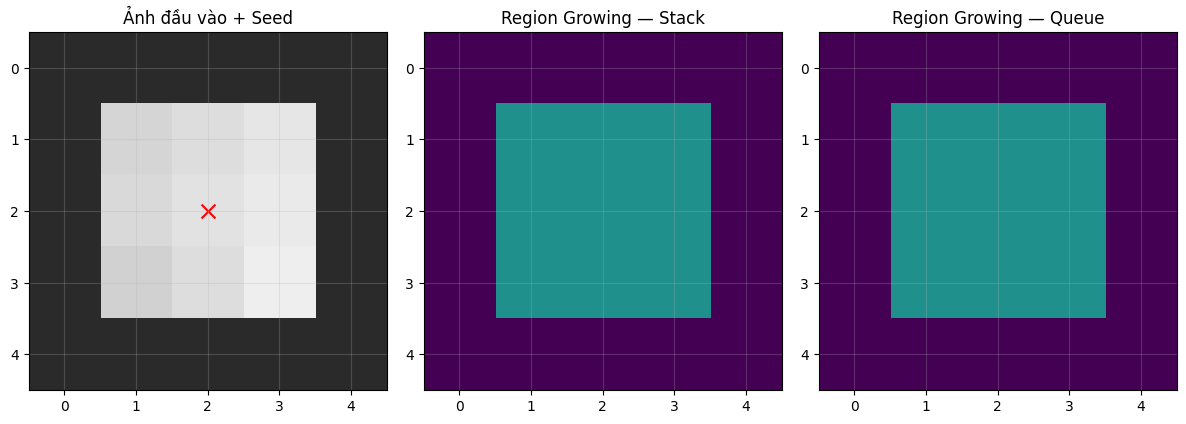

In [ ]:
# Kiểm chứng Region Growing với ảnh nhỏ

# Ảnh xám 5 × 5
img_test = np.array([
    [10, 10, 10, 10, 10],
    [10, 50, 52, 54, 10],
    [10, 51, 53, 55, 10],
    [10, 49, 52, 56, 10],
    [10, 10, 10, 10, 10]
], dtype=np.float64)

# Seed ở trung tâm
seeds_test = [(2, 2)]

# Ngưỡng chấp nhận
T_test = 5

labels_stack_test = region_growing_classic(
    img_test,
    seeds=seeds_test,
    T=T_test,
    order="stack"
)

labels_queue_test = region_growing_classic(
    img_test,
    seeds=seeds_test,
    T=T_test,
    order="queue"
)

print("=== ẢNH ĐẦU VÀO ===")
print(img_test)

print("\n=== REGION GROWING — STACK ===")
print(labels_stack_test)

print("\n=== REGION GROWING — QUEUE ===")
print(labels_queue_test)

assert labels_stack_test.shape == img_test.shape
assert labels_queue_test.shape == img_test.shape

assert labels_stack_test.dtype == np.int32
assert labels_queue_test.dtype == np.int32

assert labels_stack_test[2, 2] == 0
assert labels_queue_test[2, 2] == 0

# Nền mức xám 10 không thuộc vùng có mức xám khoảng 50
assert labels_stack_test[0, 0] == -1
assert labels_queue_test[0, 0] == -1

# Tất cả 9 pixel ở khối giữa thuộc vùng 0
assert np.all(labels_stack_test[1:4, 1:4] == 0)
assert np.all(labels_queue_test[1:4, 1:4] == 0)

different_pixels_test = np.count_nonzero(
    labels_stack_test != labels_queue_test
)

print("\n=== KẾT QUẢ KIỂM CHỨNG ===")
print("PASS: Kích thước output đúng.")
print("PASS: Kiểu dữ liệu int32.")
print("PASS: Seed được gán nhãn 0.")
print("PASS: Pixel nền giữ nhãn -1.")
print("PASS: Vùng trung tâm được mở rộng đúng.")
print("Số pixel khác nhãn:", different_pixels_test)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(img_test, cmap="gray", vmin=0, vmax=60)
axes[0].scatter([2], [2], c="red", marker="x", s=100)
axes[0].set_title("Ảnh đầu vào + Seed")

axes[1].imshow(
    labels_stack_test,
    cmap="viridis",
    vmin=-1,
    vmax=1
)
axes[1].set_title("Region Growing — Stack")

axes[2].imshow(
    labels_queue_test,
    cmap="viridis",
    vmin=-1,
    vmax=1
)
axes[2].set_title("Region Growing — Queue")

for ax in axes:
    ax.set_xticks(range(5))
    ax.set_yticks(range(5))
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 5. Kiểm chứng B4 — So sánh Stack và Queue

### 5.1. Chuẩn bị ảnh Gradient

Thí nghiệm sử dụng ảnh xám tổng hợp có kích thước 64 × 64 pixel.

Ảnh được tạo bằng sự kết hợp giữa:
- Gradient theo chiều ngang.
- Gradient theo chiều dọc.
- Biến thiên cường độ dạng sóng.
- Nhiễu Gaussian nhẹ có seed cố định để tái lập kết quả.

**Mục đích:**

Khảo sát ảnh hưởng của thứ tự duyệt Stack (LIFO) và Queue (FIFO) đến kết quả Region Growing cổ điển.

Do trung bình vùng được cập nhật sau mỗi pixel được chấp nhận, thứ tự duyệt có thể dẫn đến các kết quả phân vùng khác nhau.

**Thiết lập:**
- Kích thước ảnh: 64 × 64.
- Kết nối: 4 hướng.
- Ngưỡng T: 14.
- Sử dụng cùng ảnh và seed cho cả Stack và Queue.

**Prompt hỗ trợ AI cho phần thí nghiệm (được biên soạn lại):**

> Hãy hỗ trợ tạo một ảnh gradient xám tổng hợp 64 × 64 bằng gradient ngang, gradient dọc, thành phần sin/cos và nhiễu Gaussian có random seed cố định. Chuẩn bị seed và ngưỡng dùng chung cho thí nghiệm so sánh Region Growing theo stack và queue; trực quan hóa ảnh đầu vào.

*Lưu ý: Đây là prompt mô tả lại yêu cầu hỗ trợ, không phải bản chép nguyên văn từ lịch sử hội thoại trước đó. Nếu quy định yêu cầu prompt nguyên văn, cần thay bằng nội dung đã thực sự gửi cho AI.*

=== CHUẨN BỊ THÍ NGHIỆM B4 ===
Kích thước ảnh: (64, 64)
Kiểu dữ liệu: float64
Mức xám nhỏ nhất: 67.75
Mức xám lớn nhất: 160.75
Seeds: [(32, 32)]
Ngưỡng T: 14


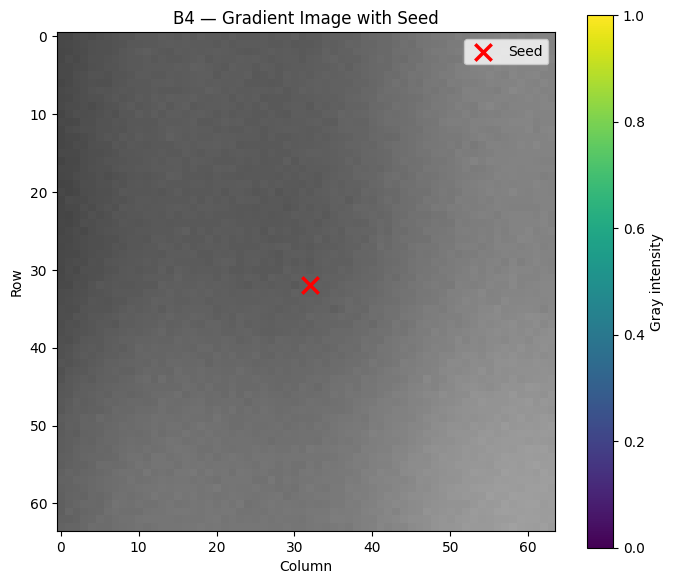

In [ ]:
height, width = 64, 64

rows, cols = np.mgrid[0:height, 0:width]

gradient_horizontal = 0.9 * cols
gradient_vertical = 0.45 * rows

wave = (
    8 * np.sin(cols / 7.0)
    + 6 * np.cos(rows / 9.0)
)

rng = np.random.default_rng(seed=42)

noise = rng.normal(
    loc=0,
    scale=1.5,
    size=(height, width)
)

gradient_img = (
    65
    + gradient_horizontal
    + gradient_vertical
    + wave
    + noise
)

# Giữ giá trị mức xám trong khoảng [0, 255]
gradient_img = np.clip(
    gradient_img,
    0,
    255
).astype(np.float64)

gradient_seeds = [
    (32, 32)
]

T_gradient = 14

print("=== CHUẨN BỊ THÍ NGHIỆM B4 ===")
print("Kích thước ảnh:", gradient_img.shape)
print("Kiểu dữ liệu:", gradient_img.dtype)
print("Mức xám nhỏ nhất:", round(gradient_img.min(), 2))
print("Mức xám lớn nhất:", round(gradient_img.max(), 2))
print("Seeds:", gradient_seeds)
print("Ngưỡng T:", T_gradient)

plt.figure(figsize=(7, 6))

plt.imshow(
    gradient_img,
    cmap="gray",
    vmin=0,
    vmax=255
)

for row, col in gradient_seeds:
    plt.scatter(
        col,
        row,
        c="red",
        marker="x",
        s=140,
        linewidths=2.5,
        label="Seed"
    )

plt.title("B4 — Gradient Image with Seed")
plt.xlabel("Column")
plt.ylabel("Row")
plt.legend()
plt.colorbar(label="Gray intensity")
plt.tight_layout()
plt.show()


### 5.2. B4 — So sánh kết quả Region Growing giữa Stack và Queue

Thực hiện Region Growing cổ điển trên cùng ảnh gradient với:
- Cùng seed tại `(32, 32)`.
- Cùng ngưỡng `T = 14`.
- Cùng kết nối 4 hướng.
- Chỉ thay đổi thứ tự xử lý: Stack (LIFO) hoặc Queue (FIFO).

Số pixel khác nhãn được xác định bằng:

$$
D = \sum_{r,c}
\mathbf{1}\left[
L_{\text{stack}}(r,c)
\neq L_{\text{queue}}(r,c)
\right]
$$

Trong đó:
- $L_{\text{stack}}$: Bản đồ nhãn từ Stack.
- $L_{\text{queue}}$: Bản đồ nhãn từ Queue.
- $D$: Tổng số pixel có nhãn khác nhau.

Mục đích là đánh giá ảnh hưởng của thứ tự duyệt đến kết quả phân vùng khi trung bình vùng được cập nhật liên tục

**Prompt hỗ trợ AI cho phần thí nghiệm (được biên soạn lại):**

> Hãy hỗ trợ thiết kế phép so sánh Region Growing stack (LIFO) và queue (FIFO) trên cùng ảnh gradient 64 × 64, seed (32, 32), T = 14 và kết nối 4 hướng. Kiểm tra output và đếm số pixel có nhãn khác nhau; trình bày bản đồ nhãn và bản đồ sai khác.

*Lưu ý: Đây là prompt mô tả lại yêu cầu hỗ trợ, không phải bản chép nguyên văn từ lịch sử hội thoại trước đó. Nếu quy định yêu cầu prompt nguyên văn, cần thay bằng nội dung đã thực sự gửi cho AI.*

=== B4: STACK VS QUEUE ===
Kích thước ảnh: (64, 64)
Seeds: [(32, 32)]
Ngưỡng T: 14

=== SỐ PIXEL THUỘC VÙNG ===
Stack: 1802
Queue: 2003

=== KHÁC BIỆT BẢN ĐỒ NHÃN ===
Tổng số pixel: 4096
Số pixel khác nhãn: 1463
Tỷ lệ khác nhãn: 35.72%


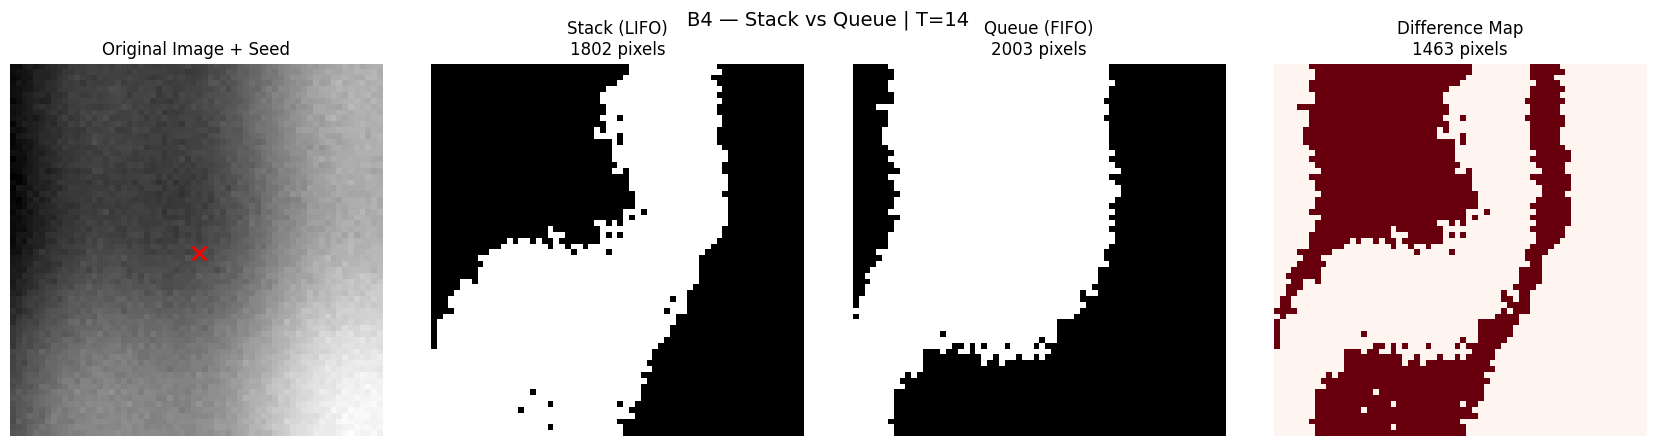


PASS: Đã so sánh Stack và Queue thành công.


In [ ]:
# B4: So sánh Stack và Queue

labels_stack = region_growing_classic(
    gradient_img,
    seeds=gradient_seeds,
    T=T_gradient,
    order="stack"
)

labels_queue = region_growing_classic(
    gradient_img,
    seeds=gradient_seeds,
    T=T_gradient,
    order="queue"
)

assert labels_stack.shape == gradient_img.shape
assert labels_queue.shape == gradient_img.shape

assert labels_stack.dtype == np.int32
assert labels_queue.dtype == np.int32

difference_mask = labels_stack != labels_queue

different_pixels = int(np.count_nonzero(difference_mask))
total_pixels = gradient_img.size

difference_percent = (
    different_pixels / total_pixels * 100
)

stack_region_pixels = int(
    np.count_nonzero(labels_stack == 0)
)

queue_region_pixels = int(
    np.count_nonzero(labels_queue == 0)
)

print("=== B4: STACK VS QUEUE ===")
print("Kích thước ảnh:", gradient_img.shape)
print("Seeds:", gradient_seeds)
print("Ngưỡng T:", T_gradient)

print("\n=== SỐ PIXEL THUỘC VÙNG ===")
print("Stack:", stack_region_pixels)
print("Queue:", queue_region_pixels)

print("\n=== KHÁC BIỆT BẢN ĐỒ NHÃN ===")
print("Tổng số pixel:", total_pixels)
print("Số pixel khác nhãn:", different_pixels)
print(f"Tỷ lệ khác nhãn: {difference_percent:.2f}%")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))

# Ảnh gốc
axes[0].imshow(gradient_img, cmap="gray")

for row, col in gradient_seeds:
    axes[0].scatter(
        col, row,
        c="red",
        marker="x",
        s=100,
        linewidths=2
    )

axes[0].set_title("Original Image + Seed")

# Stack: 0 là vùng được chọn, -1 là chưa gán
axes[1].imshow(
    labels_stack == 0,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[1].set_title(
    f"Stack (LIFO)\n{stack_region_pixels} pixels"
)

# Queue
axes[2].imshow(
    labels_queue == 0,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[2].set_title(
    f"Queue (FIFO)\n{queue_region_pixels} pixels"
)

# Bản đồ khác biệt
axes[3].imshow(
    difference_mask,
    cmap="Reds",
    vmin=0,
    vmax=1
)
axes[3].set_title(
    f"Difference Map\n{different_pixels} pixels"
)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"B4 — Stack vs Queue | T={T_gradient}",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("\nPASS: Đã so sánh Stack và Queue thành công.")


### 5.3. B4 — Khảo sát ảnh hưởng của ngưỡng T

Thí nghiệm giữ nguyên ảnh gradient, vị trí seed và kết nối 4 hướng, chỉ thay đổi ngưỡng chấp nhận pixel.

Các giá trị được khảo sát:

`T = [2, 5, 8, 11, 14, 17, 20, 25, 30]`

Với mỗi giá trị T:
1. Chạy Region Growing bằng Stack.
2. Chạy Region Growing bằng Queue.
3. Đếm số pixel được gán vào vùng.
4. Đếm số pixel có nhãn khác nhau giữa hai kết quả.

Điều kiện chấp nhận pixel:

$$
|I(q)-\mu_R| \leq T
$$

Ngưỡng T càng lớn thì điều kiện chấp nhận pixel càng ít nghiêm ngặt. Tuy nhiên, do trung bình vùng thay đổi theo quá trình mở rộng, số pixel được chọn không nhất thiết tăng đơn điệu trong mọi trường hợp.

**Prompt hỗ trợ AI cho phần thí nghiệm (được biên soạn lại):**

> Hãy hỗ trợ khảo sát các ngưỡng T = [2, 5, 8, 11, 14, 17, 20, 25, 30] đối với Region Growing theo stack và queue. Giữ nguyên ảnh và seed, đếm số pixel thuộc vùng của mỗi cách duyệt, đếm số pixel khác nhãn, tính tỷ lệ phần trăm và vẽ đồ thị so sánh.

*Lưu ý: Đây là prompt mô tả lại yêu cầu hỗ trợ, không phải bản chép nguyên văn từ lịch sử hội thoại trước đó. Nếu quy định yêu cầu prompt nguyên văn, cần thay bằng nội dung đã thực sự gửi cho AI.*

=== B4: KHẢO SÁT NGƯỠNG T ===
Kích thước ảnh: (64, 64)
Seeds: [(32, 32)]

   T |   Stack |   Queue |  Khác nhãn |  Tỷ lệ (%)
------------------------------------------------------
   2 |     171 |     155 |         76 |       1.86
   5 |     608 |    1082 |       1000 |      24.41
   8 |    1475 |    1436 |        107 |       2.61
  11 |    1942 |    1716 |        420 |      10.25
  14 |    1802 |    2003 |       1463 |      35.72
  17 |    2612 |    2304 |        848 |      20.70
  20 |    2848 |    2673 |        319 |       7.79
  25 |    3388 |    3001 |        619 |      15.11
  30 |    3650 |    3529 |        227 |       5.54

PASS: Kết quả T=14 khớp với Cell 14.


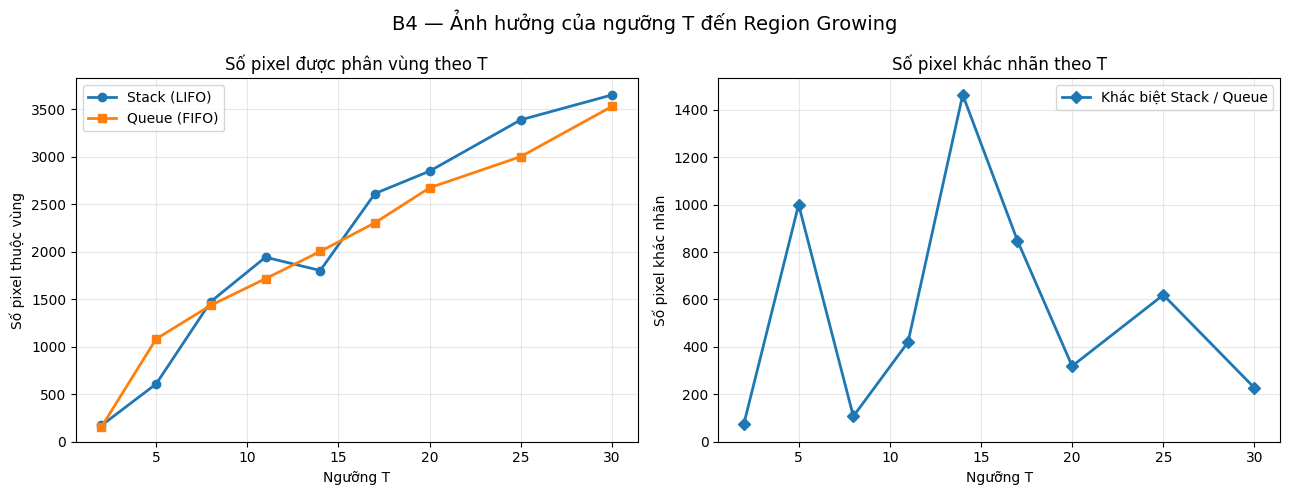

In [ ]:
# Khảo sát ảnh hưởng của ngưỡng T

T_values = [2, 5, 8, 11, 14, 17, 20, 25, 30]

stack_counts = []
queue_counts = []
difference_counts = []
difference_percents = []

total_pixels = gradient_img.size

for T in T_values:

    result_stack = region_growing_classic(
        gradient_img,
        seeds=gradient_seeds,
        T=T,
        order="stack"
    )

    result_queue = region_growing_classic(
        gradient_img,
        seeds=gradient_seeds,
        T=T,
        order="queue"
    )

    # Vì thí nghiệm chỉ có một seed nên vùng mang nhãn 0
    n_stack = int(np.count_nonzero(result_stack == 0))
    n_queue = int(np.count_nonzero(result_queue == 0))

    n_different = int(
        np.count_nonzero(result_stack != result_queue)
    )

    pct_different = n_different / total_pixels * 100

    stack_counts.append(n_stack)
    queue_counts.append(n_queue)
    difference_counts.append(n_different)
    difference_percents.append(pct_different)

print("=== B4: KHẢO SÁT NGƯỠNG T ===")
print(f"Kích thước ảnh: {gradient_img.shape}")
print(f"Seeds: {gradient_seeds}")
print()

print(
    f"{'T':>4} | {'Stack':>7} | {'Queue':>7} | "
    f"{'Khác nhãn':>10} | {'Tỷ lệ (%)':>10}"
)
print("-" * 54)

for i, T in enumerate(T_values):
    print(
        f"{T:>4} | "
        f"{stack_counts[i]:>7} | "
        f"{queue_counts[i]:>7} | "
        f"{difference_counts[i]:>10} | "
        f"{difference_percents[i]:>10.2f}"
    )

index_t14 = T_values.index(T_gradient)

assert stack_counts[index_t14] == stack_region_pixels
assert queue_counts[index_t14] == queue_region_pixels
assert difference_counts[index_t14] == different_pixels

print("\nPASS: Kết quả T=14 khớp với Cell 14.")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ 1: Số pixel được phân vùng
axes[0].plot(
    T_values,
    stack_counts,
    marker="o",
    linewidth=2,
    label="Stack (LIFO)"
)

axes[0].plot(
    T_values,
    queue_counts,
    marker="s",
    linewidth=2,
    label="Queue (FIFO)"
)

axes[0].set_title("Số pixel được phân vùng theo T")
axes[0].set_xlabel("Ngưỡng T")
axes[0].set_ylabel("Số pixel thuộc vùng")
axes[0].set_ylim(bottom=0)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Biểu đồ 2: Số pixel khác nhãn
axes[1].plot(
    T_values,
    difference_counts,
    marker="D",
    linewidth=2,
    label="Khác biệt Stack / Queue"
)

axes[1].set_title("Số pixel khác nhãn theo T")
axes[1].set_xlabel("Ngưỡng T")
axes[1].set_ylabel("Số pixel khác nhãn")
axes[1].set_ylim(bottom=0)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.suptitle(
    "B4 — Ảnh hưởng của ngưỡng T đến Region Growing",
    fontsize=14
)

plt.tight_layout()
plt.show()


### 5.4. Kiểm chứng Region Growing với nhiều Seed

Thí nghiệm sử dụng ảnh xám tổng hợp có ba vùng với cường độ khác nhau.

Các seed được đặt tại:
- Vùng 0: `(2, 2)`
- Vùng 1: `(2, 7)`
- Vùng 2: `(7, 5)`

**Mục tiêu kiểm chứng:**

1. Mỗi seed được gán đúng nhãn tương ứng.
2. Các vùng được mở rộng dựa trên ngưỡng T.
3. Pixel không thuộc vùng nào giữ nhãn `-1`.
4. Các vùng không ghi đè nhãn lên nhau.
5. Kết quả có kiểu dữ liệu `int32`.
6. So sánh kết quả khi sử dụng Stack và Queue.

**Prompt hỗ trợ AI cho phần thí nghiệm (được biên soạn lại):**

> Hãy hỗ trợ thiết kế kiểm chứng Region Growing nhiều seed trên ảnh xám 10 × 10 có ba vùng mức xám 50, 120 và 200, với seed tại (2, 2), (2, 7), (7, 5) và T = 5. Đối chiếu stack/queue, bảo đảm nhãn của seed không bị ghi đè, pixel chưa gán mang nhãn -1 và kết quả là int32.

*Lưu ý: Đây là prompt mô tả lại yêu cầu hỗ trợ, không phải bản chép nguyên văn từ lịch sử hội thoại trước đó. Nếu quy định yêu cầu prompt nguyên văn, cần thay bằng nội dung đã thực sự gửi cho AI.*

=== REGION GROWING — MULTI-SEED ===
Ảnh đầu vào:
[[  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]
 [  0.  50.  50.  50.   0.   0. 120. 120. 120.   0.]
 [  0.  50.  50.  50.   0.   0. 120. 120. 120.   0.]
 [  0.  50.  50.  50.   0.   0. 120. 120. 120.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]
 [  0.   0.   0. 200. 200. 200. 200. 200.   0.   0.]
 [  0.   0.   0. 200. 200. 200. 200. 200.   0.   0.]
 [  0.   0.   0. 200. 200. 200. 200. 200.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.]]

Bản đồ nhãn Stack:
[[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
 [-1  0  0  0 -1 -1  1  1  1 -1]
 [-1  0  0  0 -1 -1  1  1  1 -1]
 [-1  0  0  0 -1 -1  1  1  1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1  2  2  2  2  2 -1 -1]
 [-1 -1 -1  2  2  2  2  2 -1 -1]
 [-1 -1 -1  2  2  2  2  2 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1]]

Bản đồ nhãn Queue:
[[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
 [-1  0  0  0 -1

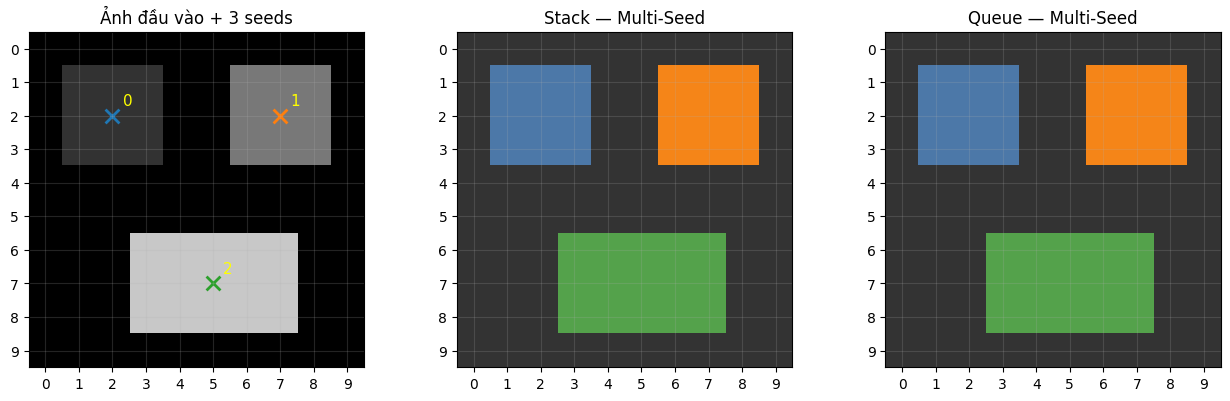

In [ ]:
# Kiểm chứng Region Growing với nhiều Seed

multi_img = np.zeros((10, 10), dtype=np.float64)

# Ba vùng có mức xám khác nhau
multi_img[1:4, 1:4] = 50
multi_img[1:4, 6:9] = 120
multi_img[6:9, 3:8] = 200

multi_seeds = [
    (2, 2),  # Vùng 0, mức xám 50
    (2, 7),  # Vùng 1, mức xám 120
    (7, 5)   # Vùng 2, mức xám 200
]

T_multi = 5

multi_labels_stack = region_growing_classic(
    multi_img,
    seeds=multi_seeds,
    T=T_multi,
    order="stack"
)

multi_labels_queue = region_growing_classic(
    multi_img,
    seeds=multi_seeds,
    T=T_multi,
    order="queue"
)

assert multi_labels_stack.shape == multi_img.shape
assert multi_labels_queue.shape == multi_img.shape

assert multi_labels_stack.dtype == np.int32
assert multi_labels_queue.dtype == np.int32

for label_id, (row, col) in enumerate(multi_seeds):
    assert multi_labels_stack[row, col] == label_id
    assert multi_labels_queue[row, col] == label_id

expected_multi = np.full(
    multi_img.shape,
    -1,
    dtype=np.int32
)

expected_multi[1:4, 1:4] = 0
expected_multi[1:4, 6:9] = 1
expected_multi[6:9, 3:8] = 2

assert np.array_equal(
    multi_labels_stack,
    expected_multi
), "Stack chưa tạo đúng bản đồ nhãn mong đợi"

assert np.array_equal(
    multi_labels_queue,
    expected_multi
), "Queue chưa tạo đúng bản đồ nhãn mong đợi"

print("=== REGION GROWING — MULTI-SEED ===")
print("Ảnh đầu vào:")
print(multi_img)

print("\nBản đồ nhãn Stack:")
print(multi_labels_stack)

print("\nBản đồ nhãn Queue:")
print(multi_labels_queue)

print("\n=== THỐNG KÊ ===")

for label_id in range(len(multi_seeds)):
    count_stack = np.count_nonzero(
        multi_labels_stack == label_id
    )

    count_queue = np.count_nonzero(
        multi_labels_queue == label_id
    )

    print(
        f"Vùng {label_id}: "
        f"Stack={count_stack}, Queue={count_queue}"
    )

unassigned = np.count_nonzero(
    multi_labels_stack == -1
)

different = np.count_nonzero(
    multi_labels_stack != multi_labels_queue
)

print("Pixel chưa gán nhãn:", unassigned)
print("Pixel khác nhãn:", different)

print("\nPASS: Cả ba seed giữ đúng nhãn.")
print("PASS: Stack và Queue tạo đúng ba vùng.")
print("PASS: Không có pixel bị ghi đè sai nhãn.")
print("PASS: Output có dtype int32.")

from matplotlib.colors import ListedColormap, BoundaryNorm

label_cmap = ListedColormap([
    "#333333",  # -1: chưa gán
    "#4C78A8",  # 0
    "#F58518",  # 1
    "#54A24B"   # 2
])

label_norm = BoundaryNorm(
    [-1.5, -0.5, 0.5, 1.5, 2.5],
    label_cmap.N
)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(multi_img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Ảnh đầu vào + 3 seeds")

for label_id, (row, col) in enumerate(multi_seeds):
    axes[0].scatter(
        col, row,
        marker="x",
        s=100,
        linewidths=2
    )
    axes[0].text(
        col + 0.3,
        row - 0.3,
        str(label_id),
        color="yellow",
        fontsize=11
    )

axes[1].imshow(
    multi_labels_stack,
    cmap=label_cmap,
    norm=label_norm
)
axes[1].set_title("Stack — Multi-Seed")

axes[2].imshow(
    multi_labels_queue,
    cmap=label_cmap,
    norm=label_norm
)
axes[2].set_title("Queue — Multi-Seed")

for ax in axes:
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()



### 5.5. Kiểm chứng các trường hợp biên của Region Growing

Thực hiện kiểm thử hàm `region_growing_classic()` với các trường hợp:

1. Seed nằm ngoài phạm vi ảnh.
2. Danh sách seed có tọa độ trùng nhau.
3. Ngưỡng T âm.
4. Ngưỡng T không hữu hạn.
5. Giá trị `order` không hợp lệ.
6. Ảnh đầu vào không phải ảnh xám hai chiều.
7. Danh sách seed rỗng.
8. Ngưỡng T bằng 0.
9. Ảnh có kích thước 1 × 1.
10. Ảnh chứa giá trị không hữu hạn.

**Tiêu chí:** Hàm phải trả về kết quả hợp lệ hoặc phát sinh `ValueError` rõ ràng theo quy ước đã thiết kế.

**Prompt hỗ trợ AI cho phần thí nghiệm (được biên soạn lại):**

> Hãy hỗ trợ bổ sung các kiểm thử biên cho hàm Region Growing đã có: seed ngoài ảnh, seed trùng, T âm hoặc không hữu hạn, order không hợp lệ, ảnh không phải grayscale, seed rỗng, T = 0, ảnh 1 × 1 và ảnh có giá trị không hữu hạn. Kiểm tra lỗi mong đợi bằng assert hoặc try/except, không sửa hàm cài đặt.

*Lưu ý: Đây là prompt mô tả lại yêu cầu hỗ trợ, không phải bản chép nguyên văn từ lịch sử hội thoại trước đó. Nếu quy định yêu cầu prompt nguyên văn, cần thay bằng nội dung đã thực sự gửi cho AI.*

In [ ]:
# Kiểm chứng các trường hợp biên Region Growing

import numpy as np

# Ảnh kiểm thử cơ bản
edge_img = np.array([
    [10, 10, 50],
    [10, 12, 50],
    [80, 80, 90]
], dtype=np.float64)

def expect_value_error(test_name, test_function):
    """Kiểm tra lời gọi có phát sinh ValueError hay không."""
    try:
        test_function()
    except ValueError:
        print(f"PASS: {test_name}")
    else:
        raise AssertionError(
            f"FAIL: {test_name} không phát sinh ValueError"
        )

# TEST 1 — Seed ngoài phạm vi ảnh

expect_value_error(
    "Seed ngoài phạm vi ảnh",
    lambda: region_growing_classic(
        edge_img,
        seeds=[(10, 10)],
        T=5
    )
)

# TEST 2 — Seed trùng nhau

expect_value_error(
    "Seed trùng nhau",
    lambda: region_growing_classic(
        edge_img,
        seeds=[(1, 1), (1, 1)],
        T=5
    )
)

# TEST 3 — Ngưỡng T âm

expect_value_error(
    "Ngưỡng T âm",
    lambda: region_growing_classic(
        edge_img,
        seeds=[(1, 1)],
        T=-1
    )
)

# TEST 4 — Ngưỡng T không hữu hạn

expect_value_error(
    "Ngưỡng T bằng vô hạn",
    lambda: region_growing_classic(
        edge_img,
        seeds=[(1, 1)],
        T=np.inf
    )
)

# TEST 5 — order không hợp lệ

expect_value_error(
    "Giá trị order không hợp lệ",
    lambda: region_growing_classic(
        edge_img,
        seeds=[(1, 1)],
        T=5,
        order="random"
    )
)

# TEST 6 — Ảnh đầu vào không phải 2D

expect_value_error(
    "Ảnh đầu vào không phải ảnh xám 2D",
    lambda: region_growing_classic(
        np.zeros((3, 3, 3)),
        seeds=[(1, 1)],
        T=5
    )
)

# TEST 7 — Danh sách seed rỗng

empty_seed_labels = region_growing_classic(
    edge_img,
    seeds=[],
    T=5
)

assert empty_seed_labels.shape == edge_img.shape
assert empty_seed_labels.dtype == np.int32
assert np.all(empty_seed_labels == -1)

print("PASS: Seed rỗng trả về toàn bộ nhãn -1.")

# TEST 8 — Ngưỡng T bằng 0

zero_t_labels = region_growing_classic(
    edge_img,
    seeds=[(0, 0)],
    T=0,
    order="queue"
)

# Ba pixel có mức xám 10 kết nối với seed
assert np.count_nonzero(zero_t_labels == 0) == 3
assert zero_t_labels[0, 0] == 0
assert zero_t_labels[0, 1] == 0
assert zero_t_labels[1, 0] == 0

# Pixel khác mức xám không được nhận vào vùng
assert zero_t_labels[1, 1] == -1

print("PASS: T=0 chỉ nhận các pixel có cùng mức xám.")

# TEST 9 — Ảnh kích thước 1 × 1

single_img = np.array([[42]], dtype=np.float64)

single_labels = region_growing_classic(
    single_img,
    seeds=[(0, 0)],
    T=0,
    order="stack"
)

assert single_labels.shape == (1, 1)
assert single_labels.dtype == np.int32
assert single_labels[0, 0] == 0

print("PASS: Ảnh 1 × 1 được xử lý đúng.")

# TEST 10 — Ảnh có NaN

nan_img = edge_img.copy()
nan_img[0, 0] = np.nan

expect_value_error(
    "Ảnh chứa NaN",
    lambda: region_growing_classic(
        nan_img,
        seeds=[(1, 1)],
        T=5
    )
)

# TỔNG KẾT

print("\n=== TỔNG KẾT CELL 17 ===")
print("PASS: 10/10 trường hợp kiểm chứng.")
print("Region Growing xử lý đúng các trường hợp đã thử.")


PASS: Seed ngoài phạm vi ảnh
PASS: Seed trùng nhau
PASS: Ngưỡng T âm
PASS: Ngưỡng T bằng vô hạn
PASS: Giá trị order không hợp lệ
PASS: Ảnh đầu vào không phải ảnh xám 2D
PASS: Seed rỗng trả về toàn bộ nhãn -1.
PASS: T=0 chỉ nhận các pixel có cùng mức xám.
PASS: Ảnh 1 × 1 được xử lý đúng.
PASS: Ảnh chứa NaN

=== TỔNG KẾT CELL 17 ===
PASS: 10/10 trường hợp kiểm chứng.
Region Growing xử lý đúng các trường hợp đã thử.


## 6. Tổng kết Region Growing cổ điển và kiểm chứng B4

### 6.1. Nội dung đã thực hiện

Đã cài đặt hàm:

`region_growing_classic(img, seeds, T, order="stack")`

Thuật toán sử dụng:
- Ảnh xám hai chiều.
- Một hoặc nhiều seed có tọa độ `(row, col)`.
- Kết nối 4 hướng: trên, dưới, trái, phải.
- Ngưỡng chấp nhận pixel T.
- Trung bình mức xám của vùng được cập nhật sau mỗi pixel được chấp nhận.
- Hai chế độ duyệt Stack (LIFO) và Queue (FIFO).

Kết quả trả về là mảng nhãn `int32` có cùng kích thước với ảnh, trong đó:
- `0, 1, 2, ...`: Nhãn các vùng tương ứng với thứ tự seed.
- `-1`: Pixel chưa được phân vùng.

### 6.2. Điều kiện phát triển vùng

Pixel ứng viên q được chấp nhận khi:

$$
|I(q)-\mu_R|\leq T
$$

Trong đó:
- $I(q)$ là giá trị mức xám của pixel ứng viên.
- $\mu_R$ là giá trị mức xám trung bình hiện tại của vùng.
- $T$ là ngưỡng chấp nhận pixel.

Khi thêm pixel mới, tổng cường độ và số lượng pixel thuộc vùng được cập nhật để tính lại trung bình vùng.

### 6.3. So sánh Stack và Queue

**Stack (LIFO):**
- Pixel được thêm sau được xử lý trước.
- Có xu hướng mở rộng sâu theo một hướng.

**Queue (FIFO):**
- Pixel được thêm trước được xử lý trước.
- Có xu hướng mở rộng theo từng lớp từ seed.

Sự khác biệt về thứ tự duyệt có thể làm thay đổi trình tự cập nhật trung bình vùng.

Do đó, hai phương pháp có thể tạo ra bản đồ nhãn khác nhau dù sử dụng cùng ảnh, cùng seed và cùng ngưỡng T.

### 6.4. Kết quả kiểm chứng

**Kiểm chứng trên ảnh 5 × 5 (Cell 12):**

- Cả Stack và Queue đều phân vùng đúng khối trung tâm.
- Pixel nền không phù hợp giữ nhãn `-1`.
- Hai phương pháp cho cùng bản đồ nhãn trong trường hợp này.

**Kiểm chứng B4 trên ảnh gradient 64 × 64 (Cell 13–14):**

- Sử dụng cùng ảnh gradient.
- Seed tại `(32, 32)`.
- Ngưỡng `T = 14`.
- So sánh bản đồ nhãn từ Stack và Queue.
- Đánh giá mức độ khác biệt bằng số pixel có nhãn khác nhau.

Công thức:

$$
D=\sum_{r,c}
\mathbf{1}
[L_{\mathrm{stack}}(r,c)\neq L_{\mathrm{queue}}(r,c)]
$$

Giá trị D thực tế được in trong Cell 14.

**Khảo sát ngưỡng T (Cell 15):**

- Thử các giá trị T từ 2 đến 30.
- Đếm số pixel được phân vùng bằng Stack và Queue.
- Đếm số pixel khác nhãn tương ứng với từng T.
- Trực quan hóa kết quả bằng hai biểu đồ.

**Kiểm chứng nhiều seed (Cell 16):**

- Sử dụng ba seed.
- Ba vùng được gán nhãn 0, 1 và 2.
- Kiểm tra việc bảo toàn nhãn seed.
- Kiểm tra các pixel chưa phân vùng giữ nhãn `-1`.
- Stack và Queue cho cùng kết quả trên ảnh mẫu gồm ba vùng đồng nhất.

**Kiểm chứng trường hợp biên (Cell 17):**

Đã kiểm thử 10 trường hợp, bao gồm:
- Seed ngoài ảnh.
- Seed trùng nhau.
- Ngưỡng T không hợp lệ.
- Chế độ order không hợp lệ.
- Ảnh đầu vào sai số chiều.
- Danh sách seed rỗng.
- Ngưỡng T bằng 0.
- Ảnh 1 × 1.
- Ảnh chứa NaN.

Các kiểm chứng trên dữ liệu mẫu đã chạy thành công.

### 6.5. Nhận xét và kết luận

Region Growing cổ điển phát triển vùng từ seed bằng cách chấp nhận những pixel lân cận có cường độ phù hợp với trung bình vùng hiện tại.

Các kết quả cho thấy:

1. Khi mức xám giữa vùng và nền khác biệt rõ rệt, Stack và Queue có thể tạo ra cùng kết quả.
2. Trên ảnh có biến thiên mức xám, thứ tự duyệt có thể ảnh hưởng đến quá trình phát triển vùng.
3. Ngưỡng T ảnh hưởng trực tiếp đến điều kiện chấp nhận pixel và kết quả phân vùng.
4. Việc gán nhãn tất cả seed trước khi mở rộng giúp bảo vệ vị trí khởi tạo của từng vùng.

Số liệu thực nghiệm trong các cell trước là cơ sở để đánh giá mức độ khác biệt giữa hai phương pháp.

### 6.6. Giới hạn của phương pháp

- Kết quả phụ thuộc vào vị trí seed.
- Ngưỡng T cần được lựa chọn phù hợp với đặc điểm ảnh.
- Trung bình vùng phụ thuộc vào các pixel đã được chấp nhận trước đó.
- Với nhiều seed, thứ tự xử lý vùng có thể ảnh hưởng đến việc phân chia các pixel nằm giữa các vùng.
- Việc sử dụng Stack và Queue không bảo đảm tạo ra kết quả khác nhau trong mọi thí nghiệm.

---

## 7. Nội dung bàn giao cho nhóm

### 7.1. Bàn giao cho Người 5 — Seeded Region Growing

Hàm được cung cấp:

`region_growing_classic(img, seeds, T, order="stack")`

Quy ước đầu vào và đầu ra:
- `img`: Mảng ảnh xám `(H, W)`.
- `seeds`: Danh sách `(row, col)`.
- `T`: Ngưỡng sai khác mức xám.
- `order`: `"stack"` hoặc `"queue"`.
- Output: Mảng nhãn `(H, W)` có dtype `int32`.
- Pixel chưa phân vùng: `-1`.
- Nhãn vùng: Bắt đầu từ `0` theo thứ tự seed.

Hàm có thể được sử dụng làm đường cơ sở để so sánh với Seeded Region Growing của Người 5.

Cần thống nhất cách xử lý khi nhiều vùng cùng có khả năng nhận một pixel.

### 7.2. Bàn giao cho Tới — Tích hợp notebook

Các thành phần của Người 4:

**Phần A — ANMS**
- Hàm `anms(points, n_keep, c_robust=0.9)`.
- Kiểm chứng ANMS trên dữ liệu mẫu.
- Thí nghiệm A5: Top-N và ANMS.
- Chỉ số Grid Occupancy.
- Khảo sát hệ số `c_robust` và số lượng điểm N.

**Phần B — Region Growing**
- Hàm `region_growing_classic(img, seeds, T, order="stack")`.
- Kiểm chứng trên ảnh xám nhỏ.
- Thí nghiệm B4: Stack và Queue.
- Biểu đồ khảo sát ngưỡng T.
- Kiểm chứng nhiều seed và các trường hợp biên.

**Yêu cầu khi tích hợp:**
- Bảo đảm thứ tự chạy các cell.
- Tránh định nghĩa trùng các hàm dùng chung.
- Sử dụng đúng quy ước tọa độ `(row, col)`.
- Thống nhất kiểu dữ liệu và cách đánh nhãn.
- Giữ lại kết quả thực nghiệm và biểu đồ.
- Chạy lại toàn bộ notebook sau khi tích hợp.

### 7.3. Kết luận

Phần Người 4 đã triển khai hai nội dung chính:

1. **ANMS:** Chọn lọc điểm góc Harris dựa trên bán kính triệt tiêu nhằm cải thiện phân bố không gian so với cách chọn Top-N trong những trường hợp phù hợp.
2. **Region Growing cổ điển:** Phân vùng ảnh dựa trên seed và trung bình vùng, hỗ trợ hai cấu trúc xử lý Stack và Queue.

Các thí nghiệm A5 và B4 cung cấp hình ảnh, phép đo định lượng và dữ liệu để so sánh các phương pháp, phục vụ việc tích hợp vào bài tập nhóm.


## 8. Kiểm chứng tổng hợp trước khi bàn giao

Thực hiện kiểm chứng cuối cùng cho phần Người 4:

1. Xác nhận hàm ANMS chọn đúng điểm theo bán kính triệt tiêu.
2. Kiểm tra đầu ra ANMS có dạng `(N, 3)`.
3. Kiểm tra Top-N và ANMS sử dụng cùng số lượng điểm trong A5.
4. Xác nhận Grid Occupancy nằm trong khoảng 0–100%.
5. Kiểm tra bản đồ nhãn Region Growing có dtype `int32`.
6. Kiểm tra nhãn seed, nhãn `-1` và kích thước output.
7. Xác nhận số pixel khác nhãn của B4.
8. Kiểm tra thí nghiệm nhiều seed.

Kết quả kiểm chứng được tổng hợp thành bảng PASS/FAIL.

**Prompt hỗ trợ AI cho phần thí nghiệm (được biên soạn lại):**

> Hãy hỗ trợ lập cell kiểm chứng tổng hợp cho ANMS và Region Growing từ các hàm đã được cài đặt. Kiểm tra hình dạng và giới hạn đầu ra, Grid Occupancy, kiểu int32 của nhãn, seed và nhãn -1, cùng chỉ số sai khác stack/queue. In PASS/FAIL và tổng số phép kiểm tra.

*Lưu ý: Đây là prompt mô tả lại yêu cầu hỗ trợ, không phải bản chép nguyên văn từ lịch sử hội thoại trước đó. Nếu quy định yêu cầu prompt nguyên văn, cần thay bằng nội dung đã thực sự gửi cho AI.*

In [ ]:
# Kiểm chứng tổng hợp

import numpy as np

checks = []

def check_result(name, condition):
    """Ghi nhận kết quả kiểm chứng PASS hoặc FAIL."""
    passed = bool(condition)
    checks.append((name, passed))

    status = "PASS" if passed else "FAIL"
    print(f"[{status}] {name}")

print("=== KIỂM CHỨNG TỔNG HỢP NGƯỜI 4 ===\n")

# A. Kiểm chứng ANMS

test_points = np.array([
    [10, 10, 100],
    [12, 10, 95],
    [50, 50, 60],
    [90, 90, 40]
], dtype=float)

original_points = test_points.copy()

anms_result = anms(
    test_points,
    n_keep=3,
    c_robust=0.9
)

expected_anms = test_points[[0, 1, 3]]

check_result(
    "ANMS chọn đúng A, B, D",
    np.array_equal(anms_result, expected_anms)
)

check_result(
    "ANMS trả về kích thước (3, 3)",
    anms_result.shape == (3, 3)
)

check_result(
    "ANMS không thay đổi input",
    np.array_equal(test_points, original_points)
)

check_result(
    "ANMS xử lý n_keep=0",
    anms(test_points, 0).shape == (0, 3)
)

check_result(
    "ANMS xử lý n_keep lớn hơn số điểm",
    anms(test_points, 100).shape == (4, 3)
)

# B. Kiểm chứng A5

final_top = top_n(candidates, n_keep=keep)

final_anms = anms(
    candidates,
    n_keep=keep,
    c_robust=0.9
)

final_top_occupancy = grid_occupancy(
    final_top,
    scene.shape,
    grid_size=(8, 8)
)

final_anms_occupancy = grid_occupancy(
    final_anms,
    scene.shape,
    grid_size=(8, 8)
)

check_result(
    "A5: Top-N và ANMS giữ cùng số điểm",
    len(final_top) == len(final_anms)
)

check_result(
    "A5: Top-N Grid Occupancy hợp lệ",
    0 <= final_top_occupancy <= 100
)

check_result(
    "A5: ANMS Grid Occupancy hợp lệ",
    0 <= final_anms_occupancy <= 100
)

# C. Kiểm chứng Region Growing

final_stack = region_growing_classic(
    img_test,
    seeds=seeds_test,
    T=T_test,
    order="stack"
)

final_queue = region_growing_classic(
    img_test,
    seeds=seeds_test,
    T=T_test,
    order="queue"
)

check_result(
    "Region Growing: kích thước output đúng",
    final_stack.shape == img_test.shape
    and final_queue.shape == img_test.shape
)

check_result(
    "Region Growing: dtype int32",
    final_stack.dtype == np.int32
    and final_queue.dtype == np.int32
)

check_result(
    "Region Growing: seed giữ nhãn 0",
    final_stack[2, 2] == 0
    and final_queue[2, 2] == 0
)

check_result(
    "Region Growing: pixel nền giữ nhãn -1",
    final_stack[0, 0] == -1
    and final_queue[0, 0] == -1
)

# D. Kiểm chứng B4

b4_stack = region_growing_classic(
    gradient_img,
    seeds=gradient_seeds,
    T=T_gradient,
    order="stack"
)

b4_queue = region_growing_classic(
    gradient_img,
    seeds=gradient_seeds,
    T=T_gradient,
    order="queue"
)

b4_different = int(
    np.count_nonzero(b4_stack != b4_queue)
)

check_result(
    "B4: bản đồ nhãn cùng kích thước ảnh",
    b4_stack.shape == gradient_img.shape
    and b4_queue.shape == gradient_img.shape
)

check_result(
    "B4: số pixel khác nhãn khớp Cell 14",
    b4_different == different_pixels
)

# E. Kiểm chứng nhiều seed

final_multi = region_growing_classic(
    multi_img,
    seeds=multi_seeds,
    T=T_multi,
    order="queue"
)

seed_labels_correct = all(
    final_multi[row, col] == label_id
    for label_id, (row, col) in enumerate(multi_seeds)
)

check_result(
    "Multi-seed: mỗi seed giữ đúng nhãn",
    seed_labels_correct
)

check_result(
    "Multi-seed: bản đồ nhãn đúng kỳ vọng",
    np.array_equal(final_multi, expected_multi)
)

# F. Tổng kết

passed_count = sum(passed for _, passed in checks)
total_count = len(checks)
failed_count = total_count - passed_count

print("\n" + "=" * 48)
print("TỔNG KẾT KIỂM CHỨNG")
print("=" * 48)

print(f"Tổng số kiểm chứng: {total_count}")
print(f"PASS: {passed_count}")
print(f"FAIL: {failed_count}")

print("\n=== KẾT QUẢ A5 ===")
print(f"Top-N Grid Occupancy: {final_top_occupancy:.2f}%")
print(f"ANMS Grid Occupancy:  {final_anms_occupancy:.2f}%")

print("\n=== KẾT QUẢ B4 ===")
print(f"Stack vs Queue: {b4_different} pixel khác nhãn")

if failed_count == 0:
    print("\nALL CHECKS PASSED")
    print("Sẵn sàng chuyển sang bước bàn giao.")
else:
    print("\nCÓ KIỂM CHỨNG CHƯA ĐẠT")
    print("Cần xem lại kết quả trước khi bàn giao.")

    for name, passed in checks:
        if not passed:
            print("FAIL:", name)


=== KIỂM CHỨNG TỔNG HỢP NGƯỜI 4 ===

[PASS] ANMS chọn đúng A, B, D
[PASS] ANMS trả về kích thước (3, 3)
[PASS] ANMS không thay đổi input
[PASS] ANMS xử lý n_keep=0
[PASS] ANMS xử lý n_keep lớn hơn số điểm
[PASS] A5: Top-N và ANMS giữ cùng số điểm
[PASS] A5: Top-N Grid Occupancy hợp lệ
[PASS] A5: ANMS Grid Occupancy hợp lệ
[PASS] Region Growing: kích thước output đúng
[PASS] Region Growing: dtype int32
[PASS] Region Growing: seed giữ nhãn 0
[PASS] Region Growing: pixel nền giữ nhãn -1
[PASS] B4: bản đồ nhãn cùng kích thước ảnh
[PASS] B4: số pixel khác nhãn khớp Cell 14
[PASS] Multi-seed: mỗi seed giữ đúng nhãn
[PASS] Multi-seed: bản đồ nhãn đúng kỳ vọng

TỔNG KẾT KIỂM CHỨNG
Tổng số kiểm chứng: 16
PASS: 16
FAIL: 0

=== KẾT QUẢ A5 ===
Top-N Grid Occupancy: 20.31%
ANMS Grid Occupancy:  29.69%

=== KẾT QUẢ B4 ===
Stack vs Queue: 1463 pixel khác nhãn

ALL CHECKS PASSED
Sẵn sàng chuyển sang bước bàn giao.


# 9. Hoàn tất và bàn giao

## 9.1. Các nhiệm vụ đã thực hiện

### Phần A — ANMS

- [x] Cài đặt `anms(points, n_keep, c_robust=0.9)`.
- [x] Kiểm chứng công thức ANMS trên dữ liệu mẫu.
- [x] So sánh Top-N và ANMS trên cùng tập điểm Harris.
- [x] Tính Grid Occupancy.
- [x] Trực quan hóa kết quả A5.
- [x] Khảo sát hệ số `c_robust` và số lượng điểm N.

### Phần B — Region Growing cổ điển

- [x] Cài đặt `region_growing_classic(img, seeds, T, order="stack")`.
- [x] Hỗ trợ Stack (LIFO) và Queue (FIFO).
- [x] Sử dụng kết nối 4 hướng.
- [x] Cập nhật trung bình vùng sau khi chấp nhận pixel.
- [x] Trả về bản đồ nhãn `int32`, sử dụng `-1` cho pixel chưa phân vùng.
- [x] Kiểm chứng Region Growing trên ảnh nhỏ.
- [x] So sánh Stack và Queue trong thí nghiệm B4.
- [x] Khảo sát ảnh hưởng của ngưỡng T.
- [x] Kiểm chứng nhiều seed.
- [x] Kiểm thử các trường hợp biên.

## 9.2. Kết quả kiểm chứng

Cell 19 đã kiểm tra tổng hợp các chức năng chính và trả về:

**ALL CHECKS PASSED**

Các kết quả thực nghiệm được lưu trong notebook, bao gồm:
- Hình so sánh Top-N và ANMS.
- Grid Occupancy của hai phương pháp.
- Biểu đồ khảo sát `c_robust` và N.
- Bản đồ phân vùng Stack và Queue.
- Bản đồ pixel khác nhãn.
- Biểu đồ khảo sát ngưỡng T.

## 9.3. Giao diện các hàm bàn giao

**ANMS**

`anms(points, n_keep, c_robust=0.9)`

- Input: Mảng `(N, 3)` gồm `(row, col, response)`.
- Output: Mảng `(M, 3)` chứa các điểm được chọn theo bán kính giảm dần.

**Region Growing cổ điển**

`region_growing_classic(img, seeds, T, order="stack")`

- Input: Ảnh xám `(H, W)`, danh sách seed `(row, col)`, ngưỡng T và chế độ duyệt.
- Output: Bản đồ nhãn `(H, W)` có kiểu `int32`.
- Nhãn chưa phân vùng: `-1`.
- Nhãn các vùng: `0, 1, 2, ...`.

## 9.4. Lưu ý khi tích hợp

1. Không định nghĩa trùng các hàm Harris cổ điển của Người 2.
2. Giữ thống nhất quy ước tọa độ `(row, col)`.
3. Thống nhất định dạng seed và bản đồ nhãn với Người 5.
4. Chạy lại toàn bộ notebook sau khi tích hợp.
5. Giữ lại các output thực nghiệm và hình minh họa.
6. Xác nhận cách khai báo và phạm vi sử dụng AI theo quy định mới của giảng viên.

## 9.5. Kết luận

Phần Này đã hoàn thành hai thuật toán ANMS và Region Growing cổ điển, cùng các thí nghiệm kiểm chứng A5 và B4.

Kết quả cung cấp các hàm và dữ liệu thực nghiệm phục vụ việc so sánh thuật toán và tích hợp vào notebook cuối cùng của nhóm.